# Mapping county health need and care indicators

This notebook is descriptive, not predictive. It compares the PLACES-based `NeedScore` with the observed CMS acute readmission rate. Readmissions are one outcome among many and should not be read as a standalone quality rating. County-level patterns are exploratory, not causal findings or official shortage/performance designations.

ER visits and Medicare spending are shown separately as utilization/resource-use context. Low ER use or spending is not automatically better, and this analysis does not measure healthcare efficiency or establish causes.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = next(
    (
        parent
        for parent in (Path.cwd(), *Path.cwd().parents)
        if (parent / "notebooks").is_dir()
        and (parent / "data").is_dir()
        and (parent / "requirements.txt").is_file()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate the healthcare-access project root.")

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 180,
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#D8DEE8",
    "grid.alpha": 0.55,
    "axes.facecolor": "white",
    "figure.facecolor": "white",
})
PALETTE = {
    "red": "#B2182B",
    "orange": "#E69F00",
    "blue": "#0072B2",
    "teal": "#009E73",
    "gray": "#7A8793",
    "light_gray": "#E5E9EF",
    "ink": "#243247",
}
county_need = pd.read_csv(PROJECT_ROOT / "data/processed/county_need_2024.csv")
cms24 = pd.read_csv(PROJECT_ROOT / "data/processed/cms24_county_small.csv")

In [2]:
county_need["CountyFIPS"] = (
    county_need["CountyFIPS"].astype(str)
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(5)
)
cms24["BENE_GEO_CD"] = (
    cms24["BENE_GEO_CD"].astype(str)
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(5)
)

analysis_df = county_need.merge(
    cms24,
    left_on="CountyFIPS",
    right_on="BENE_GEO_CD",
    how="inner",
    validate="one_to_one",
)

metric_columns = [
    "NeedScore",
    "ER_VISITS_PER_1000_BENES",
    "ACUTE_HOSP_READMSN_PCT",
    "TOT_MDCR_STDZD_PYMT_PC",
    "BENES_TOTAL_CNT",
    "BENES_OM_CNT",
    "FQHC_RHC_VISITS_PER_1000_BENES",
    "OP_VISITS_PER_1000_BENES",
    "MA_PRTCPTN_RATE",
    "BENE_DUAL_PCT",
]
for column in metric_columns:
    analysis_df[column] = pd.to_numeric(
        analysis_df[column].astype(str).str.replace(",", "", regex=False),
        errors="coerce",
    )

analysis_df["AcuteReadmissionRateDisplay"] = (
    analysis_df["ACUTE_HOSP_READMSN_PCT"] * 100
)
primary_complete = analysis_df.dropna(
    subset=["NeedScore", "ACUTE_HOSP_READMSN_PCT"]
)
three_outcome_complete = analysis_df.dropna(
    subset=[
        "NeedScore", "ACUTE_HOSP_READMSN_PCT",
        "ER_VISITS_PER_1000_BENES", "TOT_MDCR_STDZD_PYMT_PC",
    ]
)
analysis_flow = pd.DataFrame([
    {"Stage": "CDC PLACES county scores", "Counties": county_need["CountyFIPS"].nunique()},
    {"Stage": "CMS county rows", "Counties": cms24["BENE_GEO_CD"].nunique()},
    {"Stage": "County FIPS matched", "Counties": analysis_df["CountyFIPS"].nunique()},
    {"Stage": "Need + readmission complete (primary)", "Counties": len(primary_complete)},
    {"Stage": "Need + readmission + ER + spending complete (sensitivity)", "Counties": len(three_outcome_complete)},
])
display(analysis_flow)
print(
    "The plotted readmission value is the source field multiplied by 100 "
    "for display; verify the field definition and unit in the CMS data dictionary. "
    f"Q75 of displayed values = {primary_complete['AcuteReadmissionRateDisplay'].quantile(0.75):.2f}."
)

print(f"Merged counties: {len(analysis_df):,}")

,Stage,Counties
0,CDC PLACES county scores,3143
1,CMS county rows,3197
2,County FIPS matched,3142
3,Need + readmission complete (primary),2997
4,Need + readmission + ER + spending complete (s...,2996


The plotted readmission value is the source field multiplied by 100 for display; verify the field definition and unit in the CMS data dictionary. Q75 of displayed values = 18.82.
Merged counties: 3,142


## Prepare the primary comparison and sensitivity scores

The primary comparison uses NeedScore and the observed CMS readmission rate, with a cohort that requires only those two fields. Counties are not dropped from this analysis because ER visits or spending is missing. A separate complete-case sensitivity analysis compares directional summaries that assume lower readmission, ER use, and (in one version) spending are favorable. Those are assumptions for sensitivity testing—not validated quality, effectiveness, or efficiency scores.

In [3]:
care_indicators = [
    "ER_VISITS_PER_1000_BENES",
    "ACUTE_HOSP_READMSN_PCT",
    "TOT_MDCR_STDZD_PYMT_PC",
]
score_df = analysis_df[
    [
        "StateAbbr", "CountyName", "CountyFIPS", "total_population",
        "NeedScore", "BENES_TOTAL_CNT", "BENES_OM_CNT",
    "AcuteReadmissionRateDisplay", "FQHC_RHC_VISITS_PER_1000_BENES",
        "OP_VISITS_PER_1000_BENES", "MA_PRTCPTN_RATE", "BENE_DUAL_PCT",
    ]
    + care_indicators
].dropna(subset=["NeedScore", "ACUTE_HOSP_READMSN_PCT"]).copy()

sensitivity_df = score_df.dropna(subset=care_indicators).copy()
for column in care_indicators:
    sensitivity_df[f"{column}_z"] = (
        sensitivity_df[column] - sensitivity_df[column].mean()
    ) / sensitivity_df[column].std()
sensitivity_df["InverseReadmissionZ"] = -sensitivity_df[
    "ACUTE_HOSP_READMSN_PCT_z"
]
sensitivity_df["InverseReadmissionErSummary"] = -sensitivity_df[
    ["ACUTE_HOSP_READMSN_PCT_z", "ER_VISITS_PER_1000_BENES_z"]
].mean(axis=1)
sensitivity_df["InverseReadmissionErSpendingSummary"] = -sensitivity_df[
    [f"{column}_z" for column in care_indicators]
].mean(axis=1)

score_df[[
    "NeedScore", "ACUTE_HOSP_READMSN_PCT", "AcuteReadmissionRateDisplay",
]].describe().T

,count,mean,std,min,25%,50%,75%,max
NeedScore,2997.0,1.349585,2.061908,-4.557669,-0.081457,1.143779,2.8474,9.305268
ACUTE_HOSP_READMSN_PCT,2997.0,0.169567,0.030685,0.000000,0.150900,0.170100,0.1882,0.382400
AcuteReadmissionRateDisplay,2997.0,16.956730,3.068476,0.000000,15.090000,17.010000,18.8200,38.240000


## Visualize need versus the readmission rate

The chart uses the actual acute readmission rate on the vertical axis, so higher values on both axes mark counties with higher need and higher reported readmissions. The median lines are descriptive cut points, not clinical or performance standards. The high-need/high-readmission quadrant is an exploratory group for further investigation—not a designation of poor care or a causal finding.

In [4]:
need_cutoff = score_df["NeedScore"].median()
readmission_cutoff = score_df["ACUTE_HOSP_READMSN_PCT"].median()

def assign_quadrant(row):
    high_need = row["NeedScore"] >= need_cutoff
    higher_readmission_rate = row["ACUTE_HOSP_READMSN_PCT"] >= readmission_cutoff
    if high_need and higher_readmission_rate:
        return "High need / higher readmissions"
    if high_need and not higher_readmission_rate:
        return "High need / lower readmissions"
    if not high_need and higher_readmission_rate:
        return "Lower need / higher readmissions"
    return "Lower need / lower readmissions"

score_df["Quadrant"] = score_df.apply(assign_quadrant, axis=1)
score_df["Priority"] = score_df["Quadrant"].eq("High need / higher readmissions")
score_df["Quadrant"].value_counts().to_frame("count")

,count
Quadrant,
High need / higher readmissions,850
Lower need / lower readmissions,847
Lower need / higher readmissions,651
High need / lower readmissions,649


## Test stricter priority cutoffs

Median splits flag about half the counties on each axis. As a sensitivity check, define a stricter group using the top quartile of NeedScore and the top quartile of the observed readmission rate. It will usually be a subset of the median-based priority group; report the overlap and any exceptions rather than assuming that. Quantile ties can make group sizes slightly larger than exactly 25%.

In [5]:
need_q75 = score_df["NeedScore"].quantile(0.75)
readmission_q75 = score_df["ACUTE_HOSP_READMSN_PCT"].quantile(0.75)
score_df["StrictPriority"] = (
    score_df["NeedScore"].ge(need_q75)
    & score_df["ACUTE_HOSP_READMSN_PCT"].ge(readmission_q75)
)

strict_count = int(score_df["StrictPriority"].sum())
median_priority_count = int(score_df["Priority"].sum())
strict_outside_median = int(
    (score_df["StrictPriority"] & ~score_df["Priority"]).sum()
)
threshold_summary = pd.Series({
    "NeedScore 75th-percentile cutoff": need_q75,
    "Readmission-rate 75th-percentile cutoff": readmission_q75,
    "Median-based priority counties": median_priority_count,
    "Top-quartile priority counties": strict_count,
    "Median-priority group retained (%)": round(
        100 * strict_count / median_priority_count, 1
    ),
    "Strict counties outside median priority": strict_outside_median,
})
threshold_summary

NeedScore 75th-percentile cutoff             2.8474
Readmission-rate 75th-percentile cutoff      0.1882
Median-based priority counties             850.0000
Top-quartile priority counties             287.0000
Median-priority group retained (%)          33.8000
Strict counties outside median priority      0.0000
dtype: float64

In [6]:
strict_priority_counties = (
    score_df[score_df["StrictPriority"]]
    .sort_values(
        ["NeedScore", "ACUTE_HOSP_READMSN_PCT"],
        ascending=[False, False],
    )
    [[
        "StateAbbr", "CountyName", "CountyFIPS",
        "BENES_TOTAL_CNT", "BENES_OM_CNT", "NeedScore",
        "AcuteReadmissionRateDisplay", "ACUTE_HOSP_READMSN_PCT",
    ]]
)
strict_priority_counties.head(20)

,StateAbbr,CountyName,CountyFIPS,BENES_TOTAL_CNT,BENES_OM_CNT,NeedScore,AcuteReadmissionRateDisplay,ACUTE_HOSP_READMSN_PCT
2413,SD,Oglala Lakota,46102,1458.0,987.0,7.377561,23.80,0.2380
3093,WV,Mingo,54059,6843.0,1936.0,7.250990,27.50,0.2750
2587,TX,Dimmit,48127,1983.0,532.0,7.113477,24.71,0.2471
1067,KY,Magoffin,21153,3366.0,791.0,7.089987,19.88,0.1988
1543,MS,Humphreys,28053,2034.0,736.0,7.030690,22.73,0.2273
150,AR,Phillips,05107,4320.0,1552.0,6.966023,20.14,0.2014
2422,SD,Todd,46121,1019.0,713.0,6.685780,22.61,0.2261
1058,KY,Lee,21129,1841.0,459.0,6.663100,30.25,0.3025
1146,LA,Madison,22065,2102.0,912.0,6.656558,18.99,0.1899
1797,ND,Sioux,38085,459.0,234.0,6.621077,28.36,0.2836


## Check whether priority counties depend on the score definition

This is a sensitivity analysis on counties with complete readmission, ER, and spending values. It compares a readmission-only directional summary with alternatives that also include ER visits and spending. These summaries can be misleading if lower utilization reflects barriers or if spending reflects need; they are not performance rankings. The primary analysis and headline chart use actual readmission rates and the larger need-plus-readmission cohort.

In [7]:
score_definitions = {
    "Readmissions only (sensitivity)": "InverseReadmissionZ",
    "Readmissions + ER visits": "InverseReadmissionErSummary",
    "Readmissions + ER + spending": "InverseReadmissionErSpendingSummary",
}
sensitivity_need_cutoff = sensitivity_df["NeedScore"].median()
primary_priority = (
    sensitivity_df["NeedScore"].ge(sensitivity_need_cutoff)
    & sensitivity_df["InverseReadmissionZ"].lt(
        sensitivity_df["InverseReadmissionZ"].median()
    )
)
sensitivity_rows = []

for label, column in score_definitions.items():
    is_priority = (
        sensitivity_df["NeedScore"].ge(sensitivity_need_cutoff)
        & sensitivity_df[column].lt(sensitivity_df[column].median())
    )
    intersection = (is_priority & primary_priority).sum()
    union = (is_priority | primary_priority).sum()
    sensitivity_rows.append({
        "Score definition": label,
        "Priority counties": int(is_priority.sum()),
        "Same as primary": int(intersection),
        "Overlap with primary (%)": round(100 * intersection / primary_priority.sum(), 1),
        "Jaccard similarity": round(intersection / union, 3) if union else 1.0,
    })

sensitivity_table = pd.DataFrame(sensitivity_rows)
sensitivity_table

,Score definition,Priority counties,Same as primary,Overlap with primary (%),Jaccard similarity
0,Readmissions only (sensitivity),848,848,100.0,1.000
1,Readmissions + ER visits,946,763,90.0,0.740
2,Readmissions + ER + spending,973,733,86.4,0.674


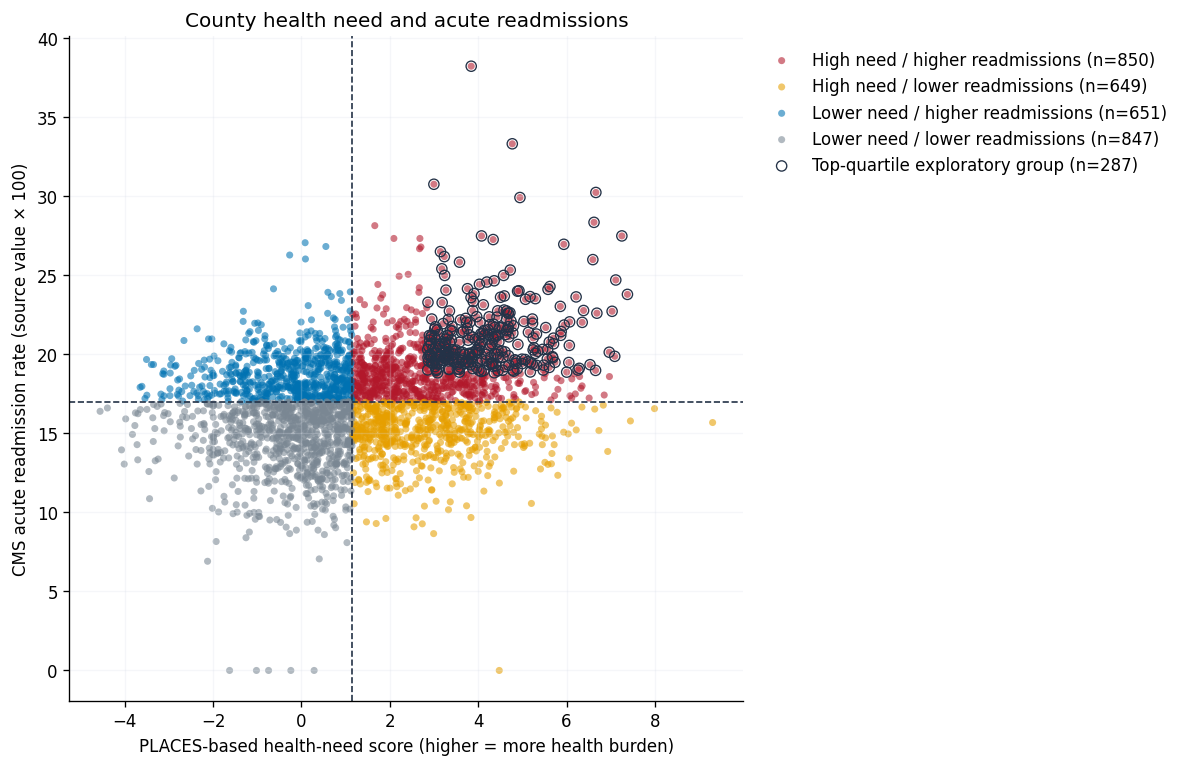

In [8]:
quadrant_colors = {
    "High need / higher readmissions": PALETTE["red"],
    "High need / lower readmissions": PALETTE["orange"],
    "Lower need / higher readmissions": PALETTE["blue"],
    "Lower need / lower readmissions": PALETTE["gray"],
}
readmission_rate_cutoff_display = score_df["AcuteReadmissionRateDisplay"].median()
fig, ax = plt.subplots(figsize=(10, 6.5))
for quadrant, group in score_df.groupby("Quadrant", observed=True):
    ax.scatter(
        group["NeedScore"],
        group["AcuteReadmissionRateDisplay"],
        s=18,
        alpha=0.58,
        label=f"{quadrant} (n={len(group):,})",
        color=quadrant_colors[quadrant],
        edgecolors="none",
    )
strict_group = score_df.loc[score_df["StrictPriority"]]
ax.scatter(
    strict_group["NeedScore"],
    strict_group["AcuteReadmissionRateDisplay"],
    s=38,
    facecolors="none",
    edgecolors=PALETTE["ink"],
    linewidths=0.8,
    label=f"Top-quartile exploratory group (n={len(strict_group):,})",
    zorder=5,
)
ax.axvline(need_cutoff, color=PALETTE["ink"], linestyle="--", linewidth=1)
ax.axhline(readmission_rate_cutoff_display, color=PALETTE["ink"], linestyle="--", linewidth=1)
ax.set_xlabel("PLACES-based health-need score (higher = more health burden)")
ax.set_ylabel("CMS acute readmission rate (source value × 100)")
ax.set_title("County health need and acute readmissions")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

In [9]:
priority_counties = (
    score_df[score_df["Priority"]]
    .sort_values(["NeedScore", "ACUTE_HOSP_READMSN_PCT"], ascending=[False, False])
    [[
        "StateAbbr", "CountyName", "CountyFIPS", "NeedScore",
        "BENES_TOTAL_CNT", "BENES_OM_CNT", "AcuteReadmissionRateDisplay",
        *care_indicators,
    ]]
)
priority_counties.head(20)

,StateAbbr,CountyName,CountyFIPS,NeedScore,BENES_TOTAL_CNT,BENES_OM_CNT,AcuteReadmissionRateDisplay,ER_VISITS_PER_1000_BENES,ACUTE_HOSP_READMSN_PCT,TOT_MDCR_STDZD_PYMT_PC
2413,SD,Oglala Lakota,46102,7.377561,1458.0,987.0,23.80,601.8237,0.2380,17629.81
3093,WV,Mingo,54059,7.250990,6843.0,1936.0,27.50,860.5372,0.2750,11085.57
2587,TX,Dimmit,48127,7.113477,1983.0,532.0,24.71,890.9774,0.2471,16632.19
1067,KY,Magoffin,21153,7.089987,3366.0,791.0,19.88,664.9810,0.1988,11434.53
1543,MS,Humphreys,28053,7.030690,2034.0,736.0,22.73,658.9674,0.2273,14724.98
61,AL,Greene,01063,6.969915,2367.0,537.0,18.60,543.7616,0.1860,11800.14
150,AR,Phillips,05107,6.966023,4320.0,1552.0,20.14,500.0000,0.2014,11653.10
35,AL,Bullock,01011,6.851676,2441.0,520.0,17.43,482.6923,0.1743,12279.03
2422,SD,Todd,46121,6.685780,1019.0,713.0,22.61,476.8583,0.2261,14267.92
1058,KY,Lee,21129,6.663100,1841.0,459.0,30.25,668.8453,0.3025,12957.29


## Check Medicare beneficiary counts before interpreting rates

The CMS file includes both total beneficiary counts and Original Medicare beneficiary counts. The notebook compares both because their quartile assignments differ; neither count is treated as the exact denominator for every outcome until that measure's documentation is checked. These are size-sensitivity checks, not formal reliability thresholds. Report the source denominator and suppressed values before interpreting a county rate.

In [10]:
denominator_count_fields = {
    "All Medicare beneficiaries (BENES_TOTAL_CNT)": "BENES_TOTAL_CNT",
    "Original Medicare beneficiaries (BENES_OM_CNT)": "BENES_OM_CNT",
}
denominator_summary_rows = []
for denominator_label, column in denominator_count_fields.items():
    for priority_status, group in score_df.groupby("Priority", observed=True):
        values = group[column].dropna()
        denominator_summary_rows.append({
            "Count field": denominator_label,
            "Median-based priority candidate": priority_status,
            "Count with data": len(values),
            "10th percentile": values.quantile(0.10),
            "25th percentile": values.quantile(0.25),
            "Median": values.median(),
            "75th percentile": values.quantile(0.75),
            "90th percentile": values.quantile(0.90),
        })
denominator_summary = pd.DataFrame(denominator_summary_rows)
display(denominator_summary.round(0))
score_df["ReadmissionZero"] = score_df["ACUTE_HOSP_READMSN_PCT"].eq(0)
zero_readmission_counties = score_df.loc[
    score_df["ReadmissionZero"],
    ["StateAbbr", "CountyName", "CountyFIPS", "BENES_TOTAL_CNT", "BENES_OM_CNT", "ACUTE_HOSP_READMSN_PCT"],
]
print(f"Counties with a reported zero readmission rate: {len(zero_readmission_counties)}.")
display(zero_readmission_counties)

,Count field,Median-based priority candidate,Count with data,10th percentile,25th percentile,Median,75th percentile,90th percentile
0,All Medicare beneficiaries (BENES_TOTAL_CNT),False,2147,1614.0,3246.0,7981.0,22422.0,63974.0
1,All Medicare beneficiaries (BENES_TOTAL_CNT),True,850,1728.0,3204.0,6172.0,11674.0,22881.0
2,Original Medicare beneficiaries (BENES_OM_CNT),False,2147,880.0,1664.0,3570.0,9992.0,25689.0
3,Original Medicare beneficiaries (BENES_OM_CNT),True,850,735.0,1360.0,2397.0,4855.0,9030.0


Counties with a reported zero readmission rate: 6.


,StateAbbr,CountyName,CountyFIPS,BENES_TOTAL_CNT,BENES_OM_CNT,ACUTE_HOSP_READMSN_PCT
1758,ND,Billings,38007,202.0,104.0,0.0
1811,NE,Banner,31007,117.0,69.0,0.0
2393,SD,Harding,46063,316.0,217.0,0.0
2655,TX,Kent,48263,221.0,111.0,0.0
2658,TX,King,48269,41.0,15.0,0.0
2744,TX,Terrell,48443,249.0,107.0,0.0


In [11]:
denominator_profile_rows = []
for denominator_label, column in denominator_count_fields.items():
    valid_counts = score_df[column].dropna()
    quartile = pd.qcut(valid_counts, q=4, duplicates="drop")
    grouped = score_df.loc[valid_counts.index].groupby(quartile, observed=True)
    for interval, group in grouped:
        denominator_profile_rows.append({
            "Count field": denominator_label,
            "Count quartile": str(interval),
            "Counties": len(group),
            "Priority candidates": int(group["Priority"].sum()),
            "Priority share (%)": 100 * group["Priority"].mean(),
            "Median readmission rate (source value × 100)": 100 * group["ACUTE_HOSP_READMSN_PCT"].median(),
        })
denominator_profile = pd.DataFrame(denominator_profile_rows)
display(denominator_profile.round(1))

bottom_quartiles = {}
for denominator_label, column in denominator_count_fields.items():
    valid_counts = score_df[column].dropna()
    quartile = pd.qcut(valid_counts, q=4, duplicates="drop")
    bottom_quartiles[denominator_label] = set(
        valid_counts.index[quartile == quartile.cat.categories[0]]
    )
total_bottom = bottom_quartiles["All Medicare beneficiaries (BENES_TOTAL_CNT)"]
om_bottom = bottom_quartiles["Original Medicare beneficiaries (BENES_OM_CNT)"]
print(
    f"Bottom-quartile membership overlap between the two available counts: "
    f"{len(total_bottom & om_bottom)} of {len(total_bottom)} (total count) and "
    f"{len(om_bottom)} (Original Medicare count)."
)

,Count field,Count quartile,Counties,Priority candidates,Priority share (%),Median readmission rate (source value × 100)
0,All Medicare beneficiaries (BENES_TOTAL_CNT),"(40.999, 3240.0]",750,214,28.5,16.2
1,All Medicare beneficiaries (BENES_TOTAL_CNT),"(3240.0, 7153.0]",749,273,36.4,16.7
2,All Medicare beneficiaries (BENES_TOTAL_CNT),"(7153.0, 18286.0]",749,244,32.6,17.0
3,All Medicare beneficiaries (BENES_TOTAL_CNT),"(18286.0, 1718250.0]",749,119,15.9,17.7
4,Original Medicare beneficiaries (BENES_OM_CNT),"(14.999, 1549.0]",750,256,34.1,16.7
5,Original Medicare beneficiaries (BENES_OM_CNT),"(1549.0, 3099.0]",750,253,33.7,16.5
6,Original Medicare beneficiaries (BENES_OM_CNT),"(3099.0, 7671.0]",748,230,30.7,17.0
7,Original Medicare beneficiaries (BENES_OM_CNT),"(7671.0, 538417.0]",749,111,14.8,17.6


Bottom-quartile membership overlap between the two available counts: 637 of 750 (total count) and 750 (Original Medicare count).


In [12]:
priority_counties.sort_values("BENES_OM_CNT").head(15)[
    [
        "StateAbbr", "CountyName", "CountyFIPS",
        "BENES_TOTAL_CNT", "BENES_OM_CNT", "NeedScore",
        "ACUTE_HOSP_READMSN_PCT", "AcuteReadmissionRateDisplay",
        "ER_VISITS_PER_1000_BENES",
    ]
]

,StateAbbr,CountyName,CountyFIPS,BENES_TOTAL_CNT,BENES_OM_CNT,NeedScore,ACUTE_HOSP_READMSN_PCT,AcuteReadmissionRateDisplay,ER_VISITS_PER_1000_BENES
2370,SD,Buffalo,46017,225.0,154.0,4.771342,0.3333,33.33,1103.8961
391,GA,Baker,13007,715.0,167.0,4.027934,0.2444,24.44,634.7305
1797,ND,Sioux,38085,459.0,234.0,6.621077,0.2836,28.36,495.7265
515,GA,Stewart,13259,1193.0,273.0,2.996872,0.3077,30.77,439.5604
2647,TX,Jim Hogg,48247,1030.0,278.0,6.197855,0.1750,17.50,920.8633
2753,TX,Upton,48461,679.0,296.0,3.962586,0.1842,18.42,864.8649
2397,SD,Jackson,46071,499.0,301.0,3.841898,0.3824,38.24,568.1063
505,GA,Quitman,13239,882.0,301.0,4.237901,0.2125,21.25,857.1429
1025,KY,Elliott,21063,1375.0,309.0,5.292729,0.2353,23.53,634.3042
1088,KY,Owsley,21189,1210.0,313.0,6.384728,0.2278,22.78,706.0703


## Compare individual indicators for priority candidates

The primary candidate label uses only NeedScore and the observed readmission rate. These boxplots compare the actual readmission, ER-use, and spending measures separately; low use or spending is not automatically better. Outlier points are hidden to keep the central distributions readable.

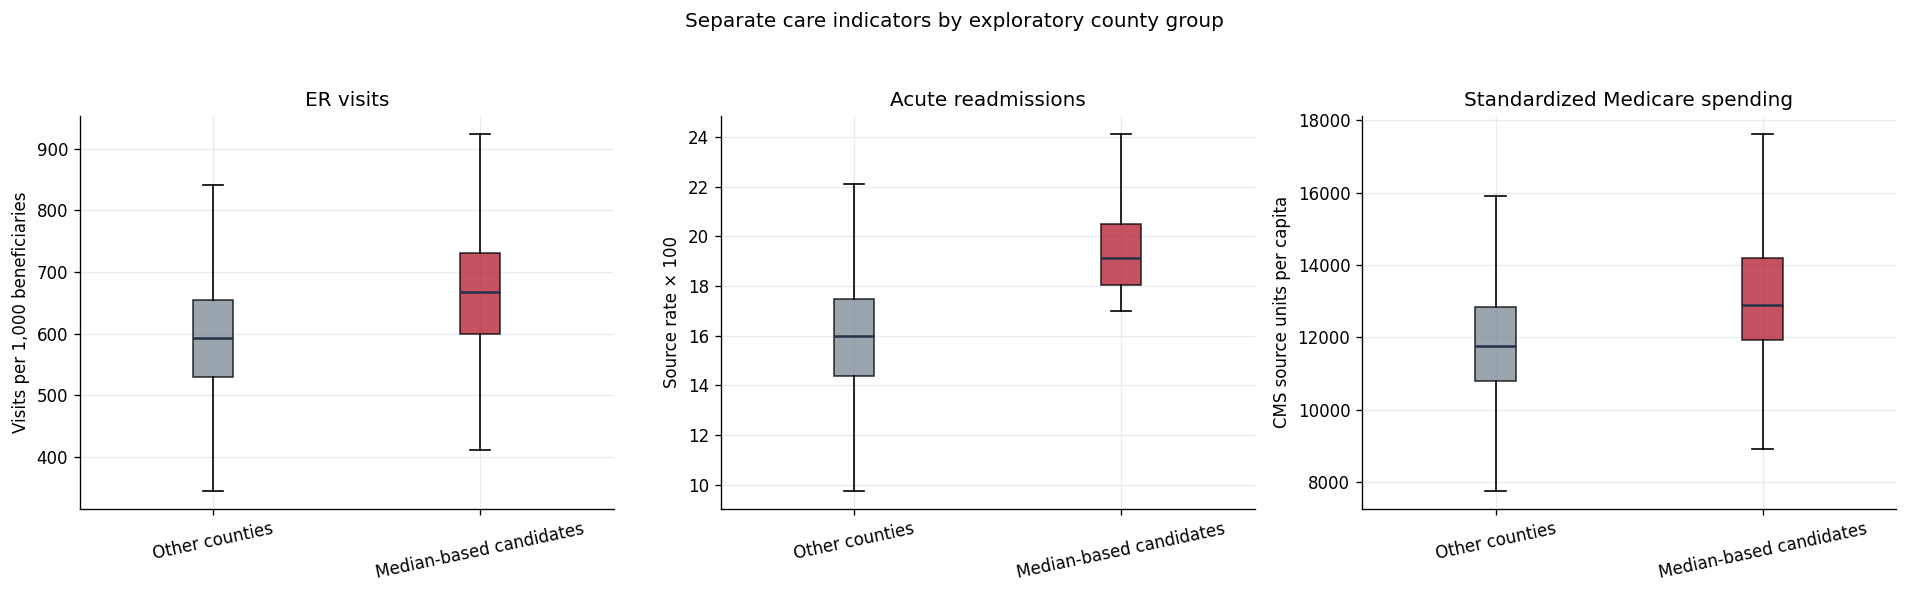

In [13]:
indicator_plots = [
    ("ER_VISITS_PER_1000_BENES", "ER visits", "Visits per 1,000 beneficiaries"),
    ("AcuteReadmissionRateDisplay", "Acute readmissions", "Source rate × 100"),
    ("TOT_MDCR_STDZD_PYMT_PC", "Standardized Medicare spending", "CMS source units per capita"),
]
candidate_labels = ["Other counties", "Median-based candidates"]
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (column, title, ylabel) in zip(axes, indicator_plots):
    values_by_group = [
        score_df.loc[~score_df["Priority"], column].dropna(),
        score_df.loc[score_df["Priority"], column].dropna(),
    ]
    boxes = ax.boxplot(
        values_by_group,
        tick_labels=candidate_labels,
        patch_artist=True,
        showfliers=False,
        medianprops={"color": PALETTE["ink"], "linewidth": 1.5},
    )
    for box, color in zip(boxes["boxes"], [PALETTE["gray"], PALETTE["red"]]):
        box.set_facecolor(color)
        box.set_alpha(0.75)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", labelrotation=12)
fig.suptitle("Separate care indicators by exploratory county group")
fig.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

## Map need, care indicators, and service-use context

These county choropleths keep each measure separate so the map does not conceal tradeoffs in a composite. They include FQHC/RHC and outpatient visit rates as service-use context; visit rates are not direct measures of provider availability or access. Strict-priority counties are outlined on those two service-use maps so their locations can be compared directly with utilization patterns. The notebook downloads the official [2024 Census TIGER/Line county boundaries](https://www2.census.gov/geo/tiger/GENZ2024/shp/cb_2024_us_county_500k.zip) and caches them under `data/raw/` (ignored by Git). Install the small shapefile reader once with `python -m pip install -r requirements-mapping.txt`. The map separates the contiguous U.S., Alaska, and Hawaii; territories are excluded. Colors are clipped to each measure's 2nd and 98th percentiles to make county patterns easier to see; use the raw data/table for extremes.

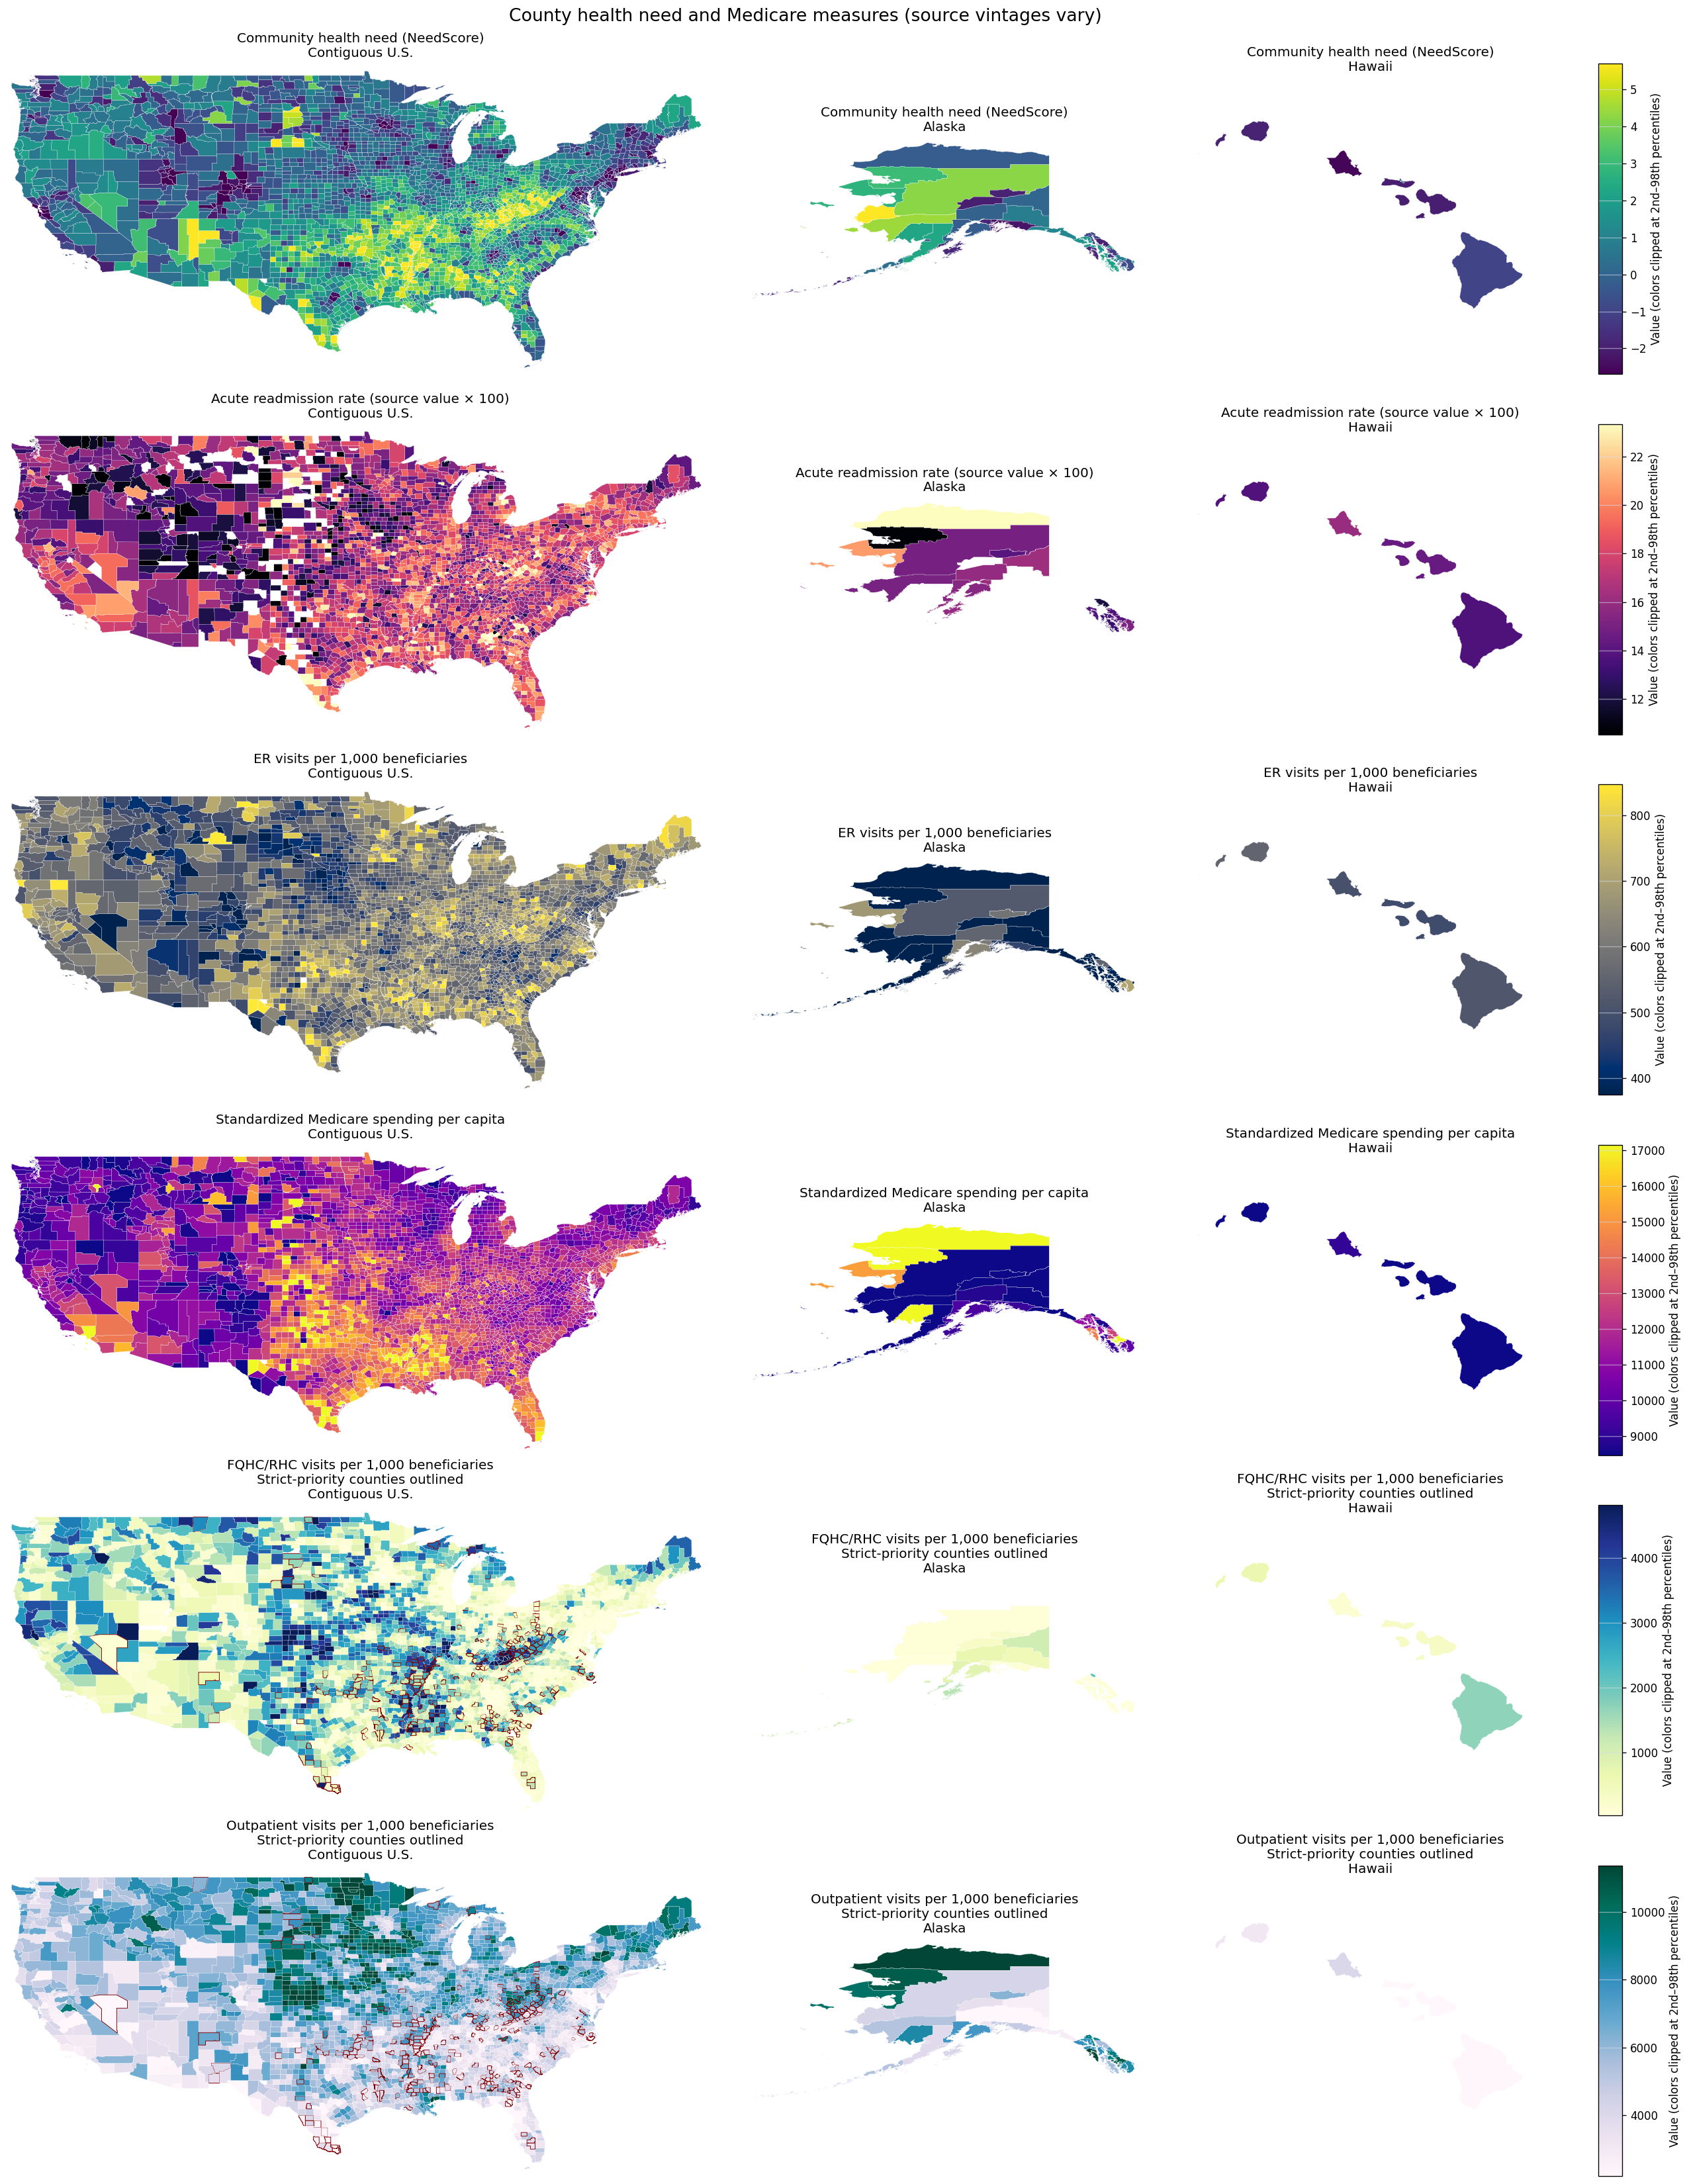

Counties with data by indicator and region:
Community health need (NeedScore):
  Contiguous U.S.: 3,107
  Alaska: 30
  Hawaii: 5
Acute readmission rate (source value × 100):
  Contiguous U.S.: 2,976
  Alaska: 17
  Hawaii: 4
ER visits per 1,000 beneficiaries:
  Contiguous U.S.: 3,106
  Alaska: 30
  Hawaii: 4
Standardized Medicare spending per capita:
  Contiguous U.S.: 3,107
  Alaska: 30
  Hawaii: 4
FQHC/RHC visits per 1,000 beneficiaries:
  Contiguous U.S.: 3,091
  Alaska: 21
  Hawaii: 4
Outpatient visits per 1,000 beneficiaries:
  Contiguous U.S.: 3,107
  Alaska: 30
  Hawaii: 4


In [14]:
import ssl
import zipfile
from pathlib import Path
from urllib.request import urlopen

import certifi
import numpy as np
import shapefile
from matplotlib.cm import ScalarMappable
from matplotlib.collections import PatchCollection
from matplotlib.colors import Normalize
from matplotlib.patches import Polygon as MapPolygon

raw_dir = PROJECT_ROOT / "data/raw"
raw_dir.mkdir(parents=True, exist_ok=True)
boundary_zip = raw_dir / "cb_2024_us_county_500k.zip"
shape_path = raw_dir / "cb_2024_us_county_500k.shp"
if not boundary_zip.exists():
    boundary_url = (
        "https://www2.census.gov/geo/tiger/GENZ2024/shp/"
        "cb_2024_us_county_500k.zip"
    )
    context = ssl.create_default_context(cafile=certifi.where())
    with urlopen(boundary_url, context=context, timeout=60) as response:
        boundary_zip.write_bytes(response.read())

if not shape_path.exists():
    with zipfile.ZipFile(boundary_zip) as archive:
        members = {Path(name).suffix.lower(): name for name in archive.namelist()}
        for extension in (".shp", ".shx", ".dbf"):
            shape_member = members.get(extension)
            if shape_member is None:
                raise FileNotFoundError(f"Missing {extension} in Census boundary archive")
            (raw_dir / f"cb_2024_us_county_500k{extension}").write_bytes(
                archive.read(shape_member)
            )

county_by_fips = analysis_df.set_index("CountyFIPS")
region_state_codes = {
    "Contiguous U.S.": None,
    "Alaska": {"02"},
    "Hawaii": {"15"},
}
territory_codes = {"60", "66", "69", "72", "78"}
region_polygons = {region: [] for region in region_state_codes}

with shapefile.Reader(str(shape_path), encoding="utf-8") as county_shapes:
    field_names = [field[0] for field in county_shapes.fields[1:]]
    for shape_record in county_shapes.iterShapeRecords():
        record = dict(zip(field_names, shape_record.record))
        state_code = str(record["STATEFP"]).zfill(2)
        county_fips = str(record["GEOID"]).zfill(5)
        if county_fips not in county_by_fips.index:
            continue
        if state_code in territory_codes:
            continue

        if state_code == "02":
            region = "Alaska"
        elif state_code == "15":
            region = "Hawaii"
        else:
            region = "Contiguous U.S."

        points = shape_record.shape.points
        part_starts = list(shape_record.shape.parts) + [len(points)]
        for start, end in zip(part_starts, part_starts[1:]):
            region_polygons[region].append((points[start:end], county_fips))

map_metrics = [
    ("NeedScore", "Community health need (NeedScore)", "viridis"),
    ("AcuteReadmissionRateDisplay", "Acute readmission rate (source value × 100)", "magma"),
    ("ER_VISITS_PER_1000_BENES", "ER visits per 1,000 beneficiaries", "cividis"),
    ("TOT_MDCR_STDZD_PYMT_PC", "Standardized Medicare spending per capita", "plasma"),
("FQHC_RHC_VISITS_PER_1000_BENES", "FQHC/RHC visits per 1,000 beneficiaries", "YlGnBu"),
("OP_VISITS_PER_1000_BENES", "Outpatient visits per 1,000 beneficiaries", "PuBuGn"),
]
service_use_map_columns = {
    "FQHC_RHC_VISITS_PER_1000_BENES",
    "OP_VISITS_PER_1000_BENES",
}
strict_priority_fips = set(
    score_df.loc[score_df["StrictPriority"], "CountyFIPS"]
)
region_limits = {
    "Contiguous U.S.": (-125, -66, 24, 50),
    "Alaska": (-180, -129, 51, 72),
    "Hawaii": (-161, -154, 18, 23),
}

fig, axes = plt.subplots(
    len(map_metrics), 4, figsize=(21, 28),
    gridspec_kw={"width_ratios": [1.35, 0.75, 0.75, 0.045]},
)
for row, (column, title, cmap) in enumerate(map_metrics):
    values = county_by_fips[column].dropna()
    lower, upper = values.quantile([0.02, 0.98])
    norm = Normalize(vmin=lower, vmax=upper, clip=True)
    for col_index, (region, limits) in enumerate(region_limits.items()):
        ax = axes[row, col_index]
        patches = []
        patch_values = []
        edge_colors = []
        line_widths = []
        for exterior, county_fips in region_polygons[region]:
            county_value = county_by_fips.at[county_fips, column]
            if pd.notna(county_value):
                patches.append(MapPolygon(exterior, closed=True))
                patch_values.append(county_value)
                if column in service_use_map_columns and county_fips in strict_priority_fips:
                    edge_colors.append("#7f0000")
                    line_widths.append(0.55)
                else:
                    edge_colors.append("white")
                    line_widths.append(0.15)

        collection = PatchCollection(
            patches, cmap=cmap, norm=norm,
            edgecolor=edge_colors, linewidth=line_widths,
        )
        collection.set_array(np.asarray(patch_values))
        ax.add_collection(collection)
        west, east, south, north = limits
        ax.set_xlim(west, east)
        ax.set_ylim(south, north)
        ax.set_aspect("equal", adjustable="box")
        map_title = title
        if column in service_use_map_columns:
            map_title += "\nStrict-priority counties outlined"
        ax.set_title(f"{map_title}\n{region}")
        ax.set_axis_off()

    colorbar = fig.colorbar(
        ScalarMappable(norm=norm, cmap=cmap),
        cax=axes[row, 3],
    )
    colorbar.set_label("Value (colors clipped at 2nd–98th percentiles)")

plt.suptitle("County health need and Medicare measures (source vintages vary)", y=0.995, fontsize=16)
fig.subplots_adjust(left=0.02, right=0.99, bottom=0.02, top=0.97, wspace=0.08, hspace=0.16)
plt.show()

print("Counties with data by indicator and region:")
for column, title, _ in map_metrics:
    print(f"{title}:")
    for region, polygons in region_polygons.items():
        region_fips = {fips for _, fips in polygons}
        data_count = sum(
            pd.notna(county_by_fips.at[fips, column]) for fips in region_fips
        )
        print(f"  {region}: {data_count:,}")

## Map the priority quadrants

This map shows the primary comparison using NeedScore and the CMS readmission rate. Counties without either of those two values are unclassified; they are not removed because an ER or spending measure is missing. Other charts use their own complete-case subsets and report their sample sizes.

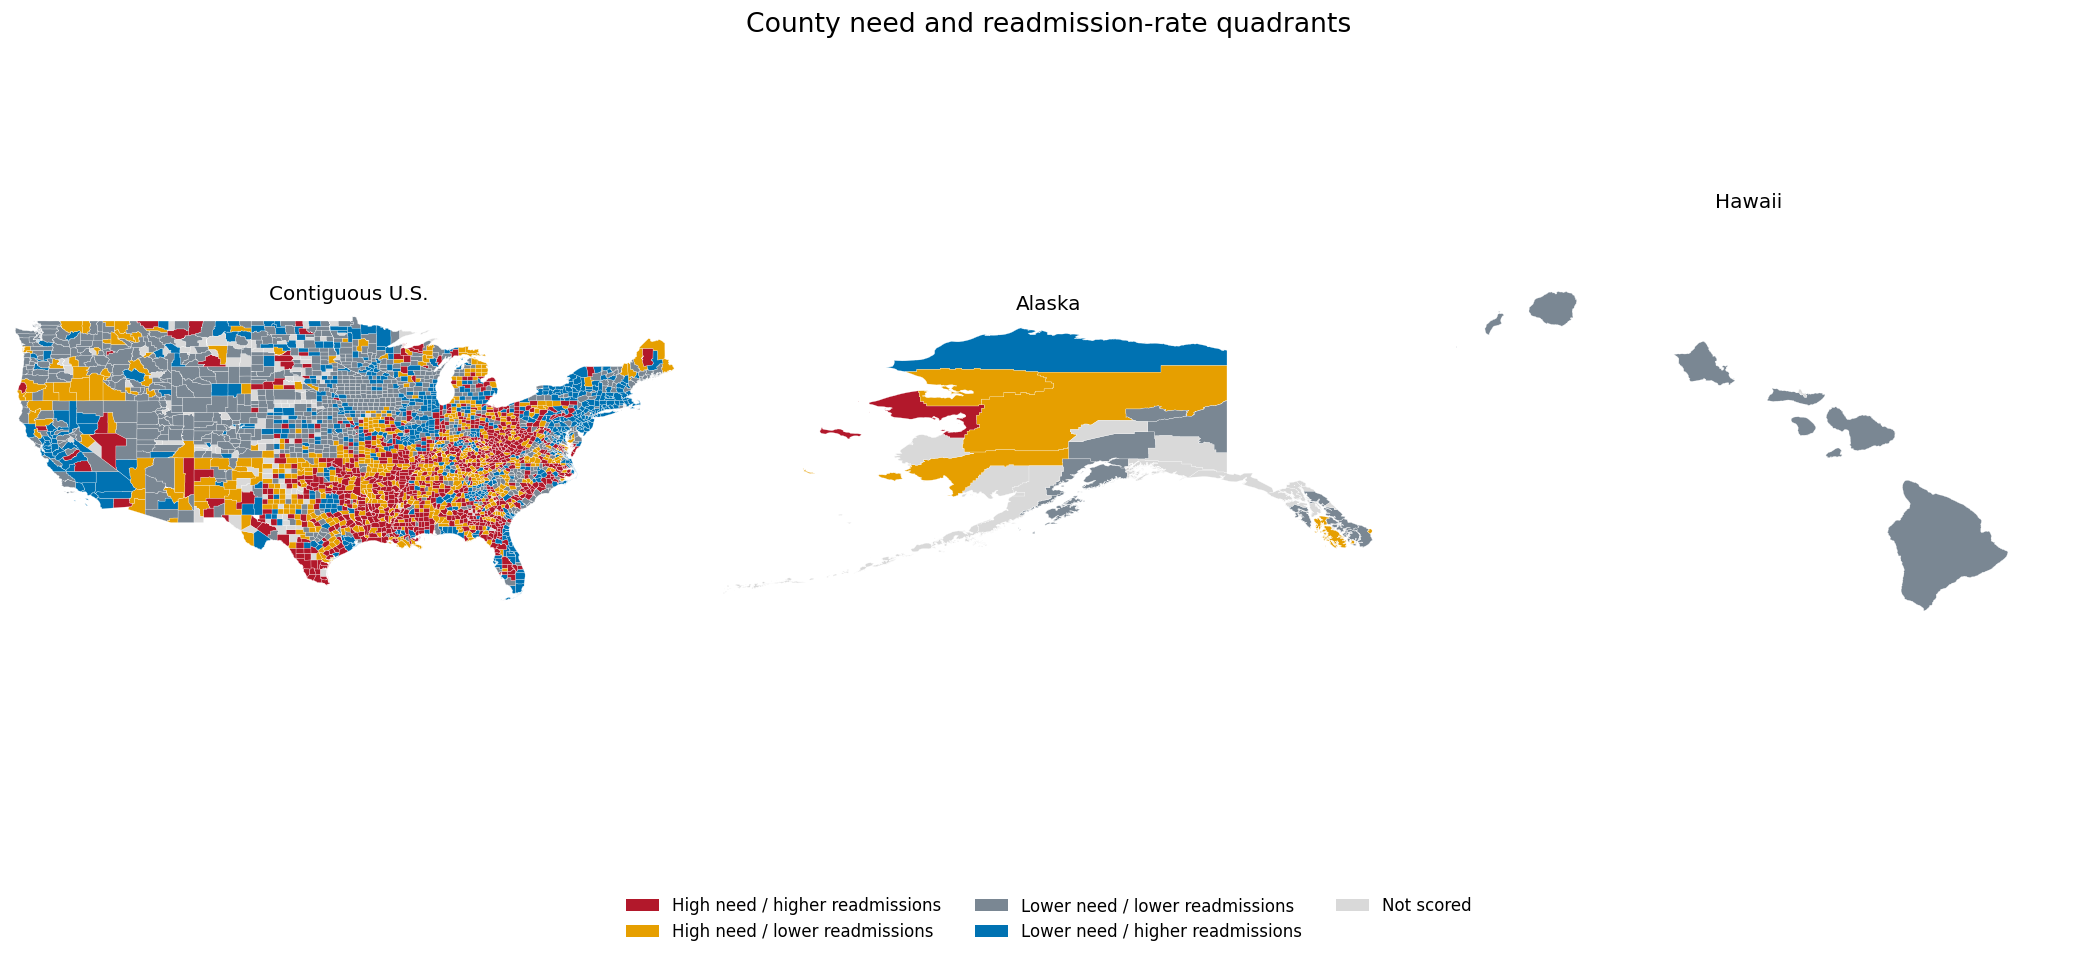

Counties scored: 2,997; not scored: 145


In [15]:
from matplotlib.patches import Patch

quadrant_colors = {
    "High need / higher readmissions": PALETTE["red"],
    "High need / lower readmissions": PALETTE["orange"],
    "Lower need / lower readmissions": PALETTE["gray"],
    "Lower need / higher readmissions": PALETTE["blue"],
}
not_scored_color = "#d9d9d9"
quadrant_by_fips = score_df.set_index("CountyFIPS")["Quadrant"]

fig, axes = plt.subplots(1, 3, figsize=(18, 8))
for ax, (region, limits) in zip(axes, region_limits.items()):
    patches = []
    facecolors = []
    for vertices, county_fips in region_polygons[region]:
        patches.append(MapPolygon(vertices, closed=True))
        quadrant = quadrant_by_fips.get(county_fips)
        facecolors.append(quadrant_colors.get(quadrant, not_scored_color))

    collection = PatchCollection(
        patches,
        facecolors=facecolors,
        edgecolor="white",
        linewidth=0.15,
    )
    ax.add_collection(collection)
    west, east, south, north = limits
    ax.set_xlim(west, east)
    ax.set_ylim(south, north)
    ax.set_aspect("equal", adjustable="box")
    ax.set_title(region)
    ax.set_axis_off()

legend_items = [
    Patch(facecolor=color, label=label)
    for label, color in quadrant_colors.items()
]
legend_items.append(Patch(facecolor=not_scored_color, label="Not scored"))
fig.legend(handles=legend_items, loc="lower center", ncol=3, frameon=False)
fig.suptitle("County need and readmission-rate quadrants", fontsize=16)
fig.subplots_adjust(left=0.02, right=0.98, bottom=0.15, top=0.88, wspace=0.04)
plt.show()

print(f"Counties scored: {len(score_df):,}; not scored: {len(analysis_df) - len(score_df):,}")

## Map the stricter priority group

This view focuses on the stricter top-quartile definition: high NeedScore and high observed readmission rate. Red counties meet both cutoffs, gray counties have scores but do not meet both, and light gray counties lack complete scores. The map is a locator for further investigation, not a measure of quality or a causal explanation.

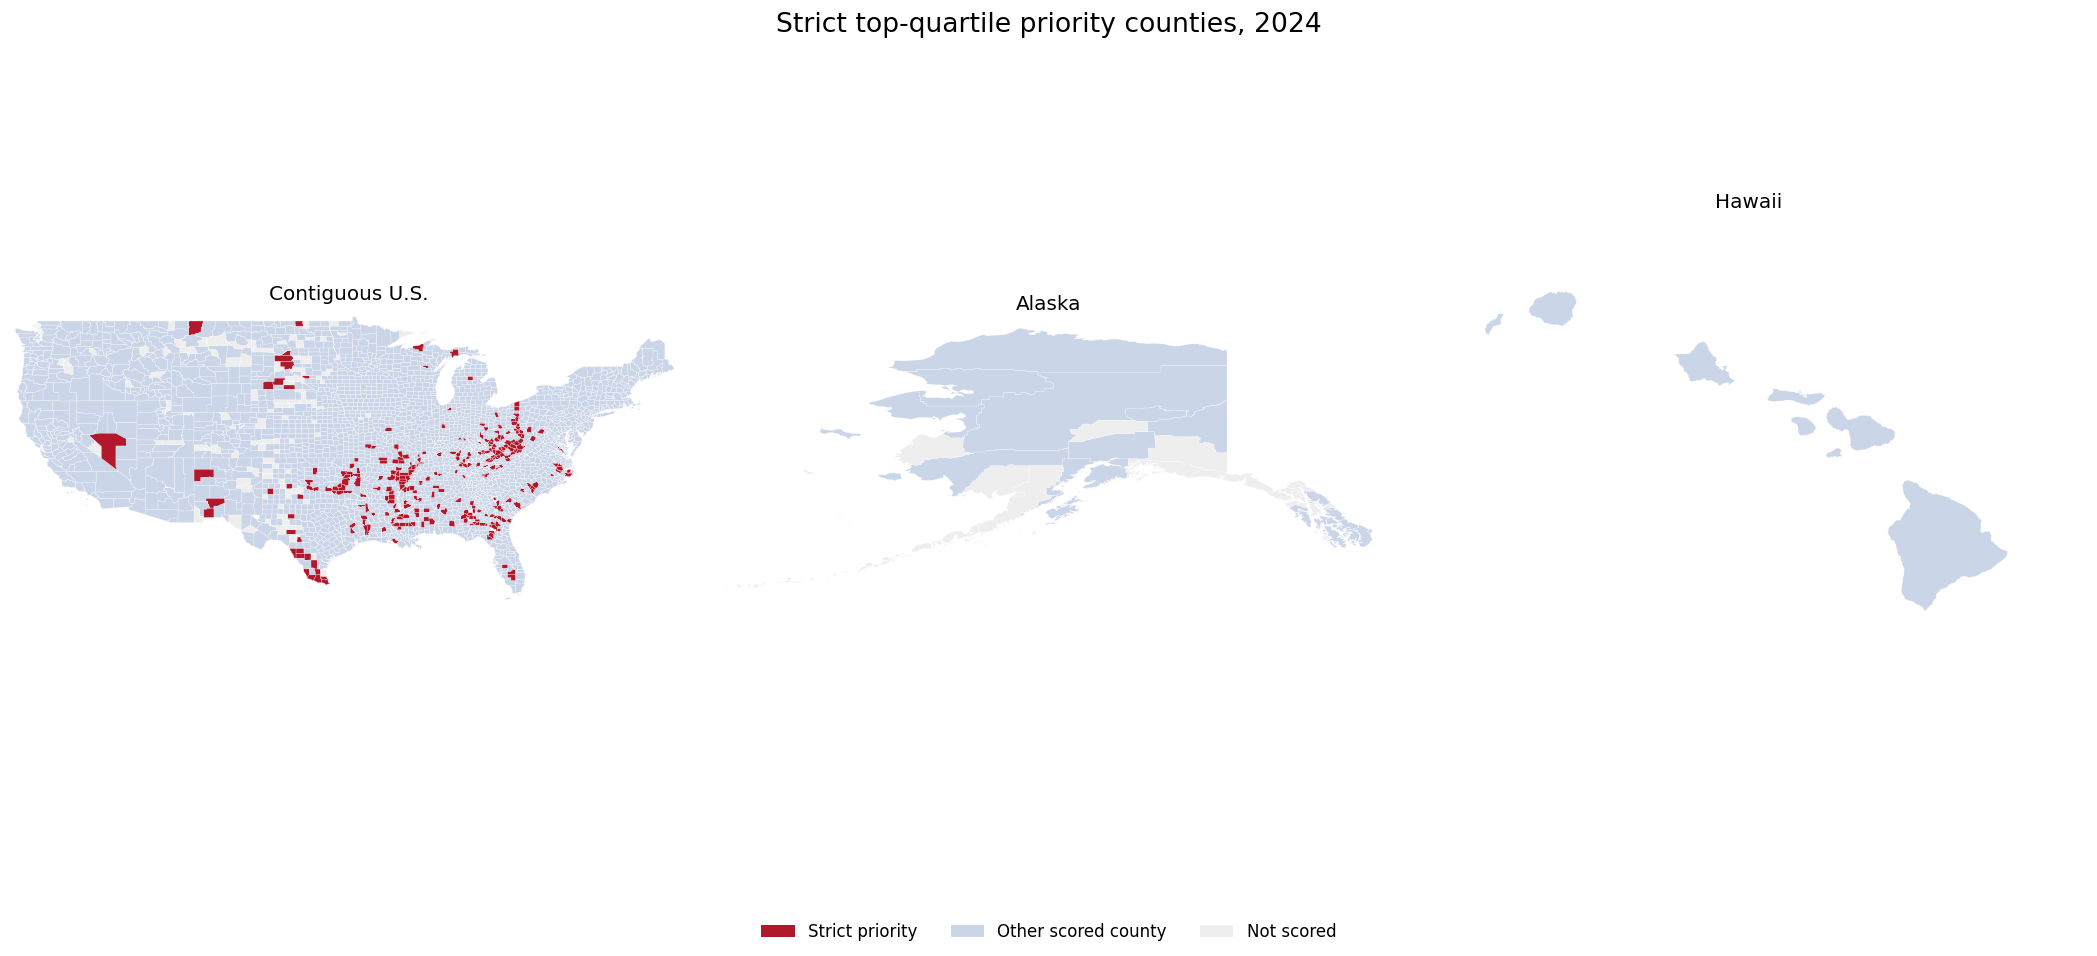

Strict priority counties mapped: 287


In [16]:
strict_by_fips = score_df.set_index("CountyFIPS")["StrictPriority"]
strict_colors = {
    "Strict priority": "#b2182b",
    "Other scored county": "#cbd5e8",
    "Not scored": "#eeeeee",
}

fig, axes = plt.subplots(1, 3, figsize=(18, 8))
for ax, (region, limits) in zip(axes, region_limits.items()):
    patches = []
    facecolors = []
    for vertices, county_fips in region_polygons[region]:
        patches.append(MapPolygon(vertices, closed=True))
        if county_fips not in strict_by_fips.index:
            status = "Not scored"
        elif strict_by_fips.at[county_fips]:
            status = "Strict priority"
        else:
            status = "Other scored county"
        facecolors.append(strict_colors[status])

    collection = PatchCollection(
        patches,
        facecolors=facecolors,
        edgecolor="white",
        linewidth=0.15,
    )
    ax.add_collection(collection)
    west, east, south, north = limits
    ax.set_xlim(west, east)
    ax.set_ylim(south, north)
    ax.set_aspect("equal", adjustable="box")
    ax.set_title(region)
    ax.set_axis_off()

strict_legend = [
    Patch(facecolor=color, label=label)
    for label, color in strict_colors.items()
]
fig.legend(handles=strict_legend, loc="lower center", ncol=3, frameon=False)
fig.suptitle("Strict top-quartile priority counties, 2024", fontsize=16)
fig.subplots_adjust(left=0.02, right=0.98, bottom=0.15, top=0.88, wspace=0.04)
plt.show()

print(f"Strict priority counties mapped: {int(score_df['StrictPriority'].sum()):,}")

## Summarize strict priority counties by state

The table reports both counts and shares among counties with complete data. A state with a high share may have only a few scored counties, so read the denominator alongside the percentage.

In [17]:
strict_state_profile = (
    score_df.groupby("StateAbbr")
    .agg(
        Counties_scored=("CountyFIPS", "count"),
        Strict_priority_counties=("StrictPriority", "sum"),
        Strict_priority_share=("StrictPriority", "mean"),
    )
)
strict_state_profile["Strict_priority_share_pct"] = (
    100 * strict_state_profile["Strict_priority_share"]
).round(1)
strict_state_profile.sort_values(
    ["Strict_priority_counties", "Strict_priority_share"],
    ascending=False,
).head(15).drop(columns="Strict_priority_share")

,Counties_scored,Strict_priority_counties,Strict_priority_share_pct
StateAbbr,,,
GA,151,29,19.2
KY,119,27,22.7
WV,55,26,47.3
TX,227,24,10.6
MS,81,22,27.2
AR,75,20,26.7
OK,76,20,26.3
TN,95,16,16.8
OH,88,14,15.9


## Compare service-use context across priority tiers

The CMS file also reports FQHC/RHC visits, outpatient visits, Medicare Advantage participation, and dual eligibility. These help describe how priority counties differ, but visit rates are utilization—not direct provider-supply or access measures. Higher or lower use is not inherently better. The tiers distinguish strict top-quartile priority counties, the remaining median-based priority group, and other scored counties.

In [18]:
priority_tier_order = [
    "Strict priority",
    "Median priority, not strict",
    "Other counties",
]
score_df["PriorityTier"] = "Other counties"
score_df.loc[score_df["Priority"], "PriorityTier"] = "Median priority, not strict"
score_df.loc[score_df["StrictPriority"], "PriorityTier"] = "Strict priority"
score_df["PriorityTier"] = pd.Categorical(
    score_df["PriorityTier"],
    categories=priority_tier_order,
    ordered=True,
)

context_indicators = {
    "FQHC/RHC visits per 1,000 beneficiaries": "FQHC_RHC_VISITS_PER_1000_BENES",
    "Outpatient visits per 1,000 beneficiaries": "OP_VISITS_PER_1000_BENES",
    "Medicare Advantage participation (CMS units)": "MA_PRTCPTN_RATE",
    "Dual eligibility (CMS units)": "BENE_DUAL_PCT",
}
context_rows = []
for tier in priority_tier_order:
    group = score_df.loc[score_df["PriorityTier"] == tier]
    for label, column in context_indicators.items():
        values = group[column].dropna()
        context_rows.append({
            "Priority tier": tier,
            "Indicator": label,
            "Count with data": len(values),
            "Median": values.median(),
            "25th percentile": values.quantile(0.25),
            "75th percentile": values.quantile(0.75),
        })

context_profile = pd.DataFrame(context_rows)
context_profile.round(3)

,Priority tier,Indicator,Count with data,Median,25th percentile,75th percentile
0,Strict priority,"FQHC/RHC visits per 1,000 beneficiaries",285,1560.440,806.203,2700.309
1,Strict priority,"Outpatient visits per 1,000 beneficiaries",287,4741.279,3666.784,6256.531
2,Strict priority,Medicare Advantage participation (CMS units),287,0.556,0.475,0.639
3,Strict priority,Dual eligibility (CMS units),287,0.180,0.147,0.222
4,"Median priority, not strict","FQHC/RHC visits per 1,000 beneficiaries",562,1149.031,383.501,2287.611
5,"Median priority, not strict","Outpatient visits per 1,000 beneficiaries",563,5144.934,3965.257,6704.310
6,"Median priority, not strict",Medicare Advantage participation (CMS units),562,0.525,0.441,0.604
7,"Median priority, not strict",Dual eligibility (CMS units),563,0.141,0.110,0.181
8,Other counties,"FQHC/RHC visits per 1,000 beneficiaries",2137,809.405,198.632,2253.420
9,Other counties,"Outpatient visits per 1,000 beneficiaries",2147,5796.434,4152.221,7686.881


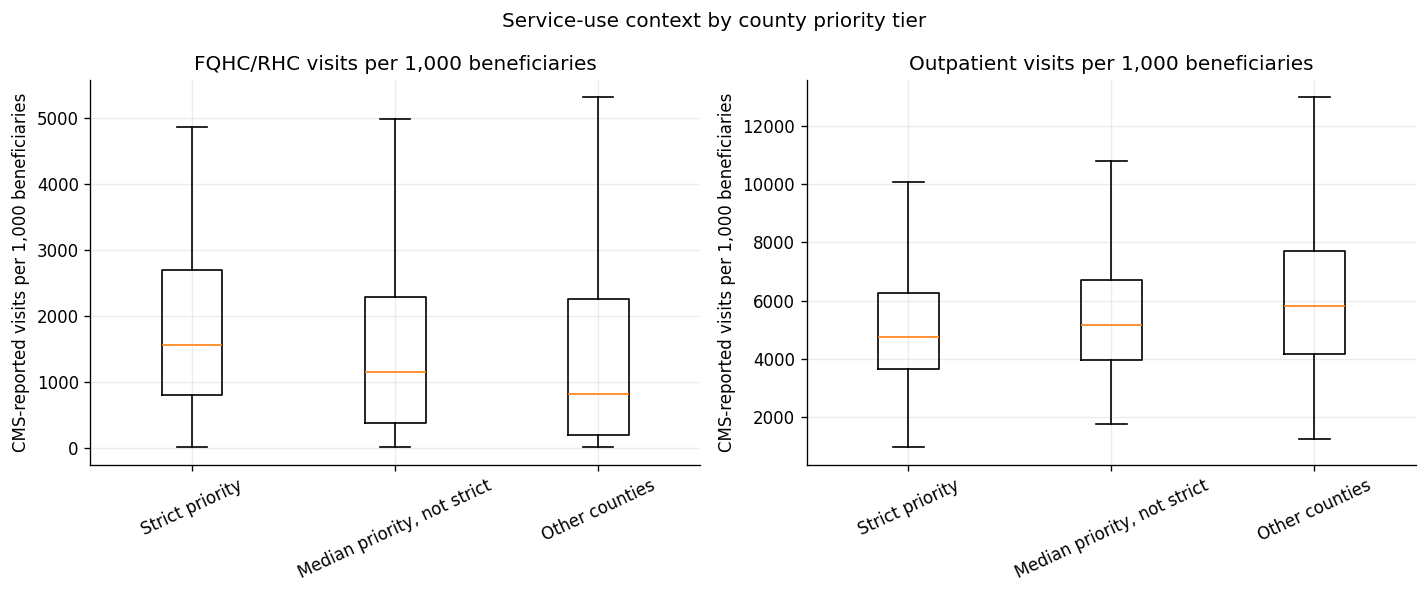

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
service_use_metrics = [
    ("FQHC_RHC_VISITS_PER_1000_BENES", "FQHC/RHC visits per 1,000 beneficiaries"),
    ("OP_VISITS_PER_1000_BENES", "Outpatient visits per 1,000 beneficiaries"),
]
for ax, (column, title) in zip(axes, service_use_metrics):
    tier_values = [
        score_df.loc[score_df["PriorityTier"] == tier, column].dropna()
        for tier in priority_tier_order
    ]
    ax.boxplot(tier_values, tick_labels=priority_tier_order, showfliers=False)
    ax.set_title(title)
    ax.set_ylabel("CMS-reported visits per 1,000 beneficiaries")
    ax.tick_params(axis="x", labelrotation=25)
fig.suptitle("Service-use context by county priority tier")
fig.tight_layout()
plt.show()

## Summarize priority candidates by state

State totals use the primary need-plus-readmission cohort; the ER and spending fields do not determine inclusion. Priority share is more comparable than raw priority count, but neither is a state ranking. County counts and data completeness differ.

In [20]:
state_profile = (
    score_df.groupby("StateAbbr")
    .agg(
        Counties_scored=("CountyFIPS", "count"),
        Priority_counties=("Priority", "sum"),
        Priority_share=("Priority", "mean"),
        Median_NeedScore=("NeedScore", "median"),
        Median_readmission_rate=("ACUTE_HOSP_READMSN_PCT", "median"),
    )
)
state_profile["Priority_share_pct"] = (100 * state_profile["Priority_share"]).round(1)
state_profile.sort_values(
    ["Priority_share", "Priority_counties"], ascending=False
).head(15).drop(columns="Priority_share")

,Counties_scored,Priority_counties,Median_NeedScore,Median_readmission_rate,Priority_share_pct
StateAbbr,,,,,
WV,55,44,4.075167,0.19710,80.0
MS,81,53,3.409559,0.18510,65.4
LA,64,39,3.014045,0.17785,60.9
OK,76,43,3.250718,0.17730,56.6
KY,119,64,3.330597,0.18050,53.8
OH,88,46,2.125332,0.17785,52.3
AR,75,39,3.953904,0.17080,52.0
AL,67,34,3.146339,0.17430,50.7
GA,151,70,2.044559,0.18420,46.4


## Quantify below-median service-use overlap

The maps show where visit rates occur; this comparison summarizes how often each priority tier is below the scored-county median for each measure. Each percentage uses only counties in that tier with a reported value. “Below median” describes utilization relative to this dataset, not inadequate access or unmet need.

## Check sensitivity to beneficiary counts

This sensitivity check separately excludes the bottom quartile under each available CMS beneficiary count (total and Original Medicare), while keeping the scored-county visit-rate medians fixed. The resulting differences show whether county-size choice affects the descriptive pattern. They do not prove either count is the rate's exact denominator or establish statistical reliability.

## View the two service-use indicators together

This scatterplot includes only counties with both visit rates reported. Each point is a county, colored by priority tier; dashed lines mark the scored-county medians used above. Both axes use a logarithmic scale because the visit rates are right-skewed and positive in this analytic set. On a log scale, equal distances represent ratios rather than equal absolute differences. The plot describes utilization patterns, not access or care quality.

## Map combinations of service-use rates

This categorical map translates the scatterplot's median lines into four county groups: below or at/above the scored-county median on each visit-rate measure. Dark red outlines mark strict-priority counties. Gray counties lack one or both visit rates in the scored analysis. These are utilization patterns only—not access or performance ratings.

## Compare service-use patterns as shares

The map and count table show where each combination occurs. This 100% stacked chart and table show each combination's share within its priority tier, so tiers with different county counts can be compared fairly. Only counties with both visit rates reported are included.

## Build an exploratory county follow-up list

This list isolates strict-priority counties that are below the scored-county median on both visit measures. It is a starting point for checking local context—not a designation of underserved counties. The table keeps beneficiary counts and observed rates visible so small denominators and differing local circumstances can be considered.

## Compare the shortlist with HRSA primary-care shortage designations

As an additional context check, this section uses the [HRSA Primary Care HPSA detail file](https://data.hrsa.gov/DataDownload/DD_Files/BCD_HPSA_FCT_DET_PC.csv), available from the [HRSA Data Downloads catalog](https://data.hrsa.gov/data/download?data=SHORT). It flags a county when the current snapshot lists at least one **Designated** Primary Care **Geographic HPSA** or **High Needs Geographic HPSA** record under that county FIPS. Population- and facility-specific designations are excluded. The county flag does not mean the whole county is covered by a shortage designation, and no record does not prove access is adequate. HRSA refreshes this data daily, so it is a current context snapshot—not a measure aligned to the 2024 CMS data.

Active primary-care geographic HPSA records matched to 992 counties in the merged project data.


,County group,Counties,With active geographic primary-care HPSA,Share with designation (%)
0,Follow-up shortlist,63,27,42.9
1,Other strict-priority counties,224,76,33.9
2,Other scored counties,2710,792,29.2


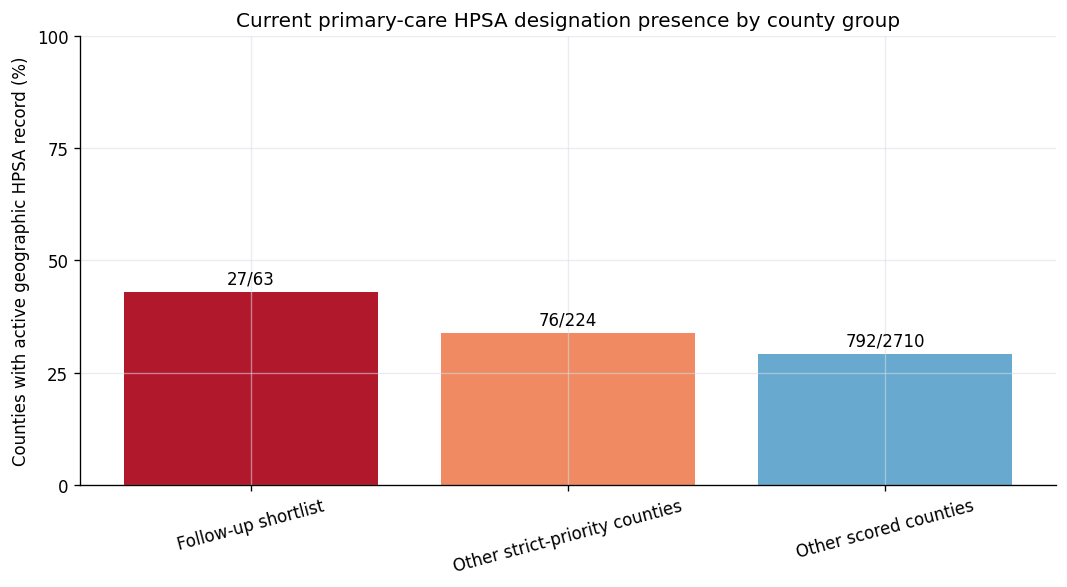

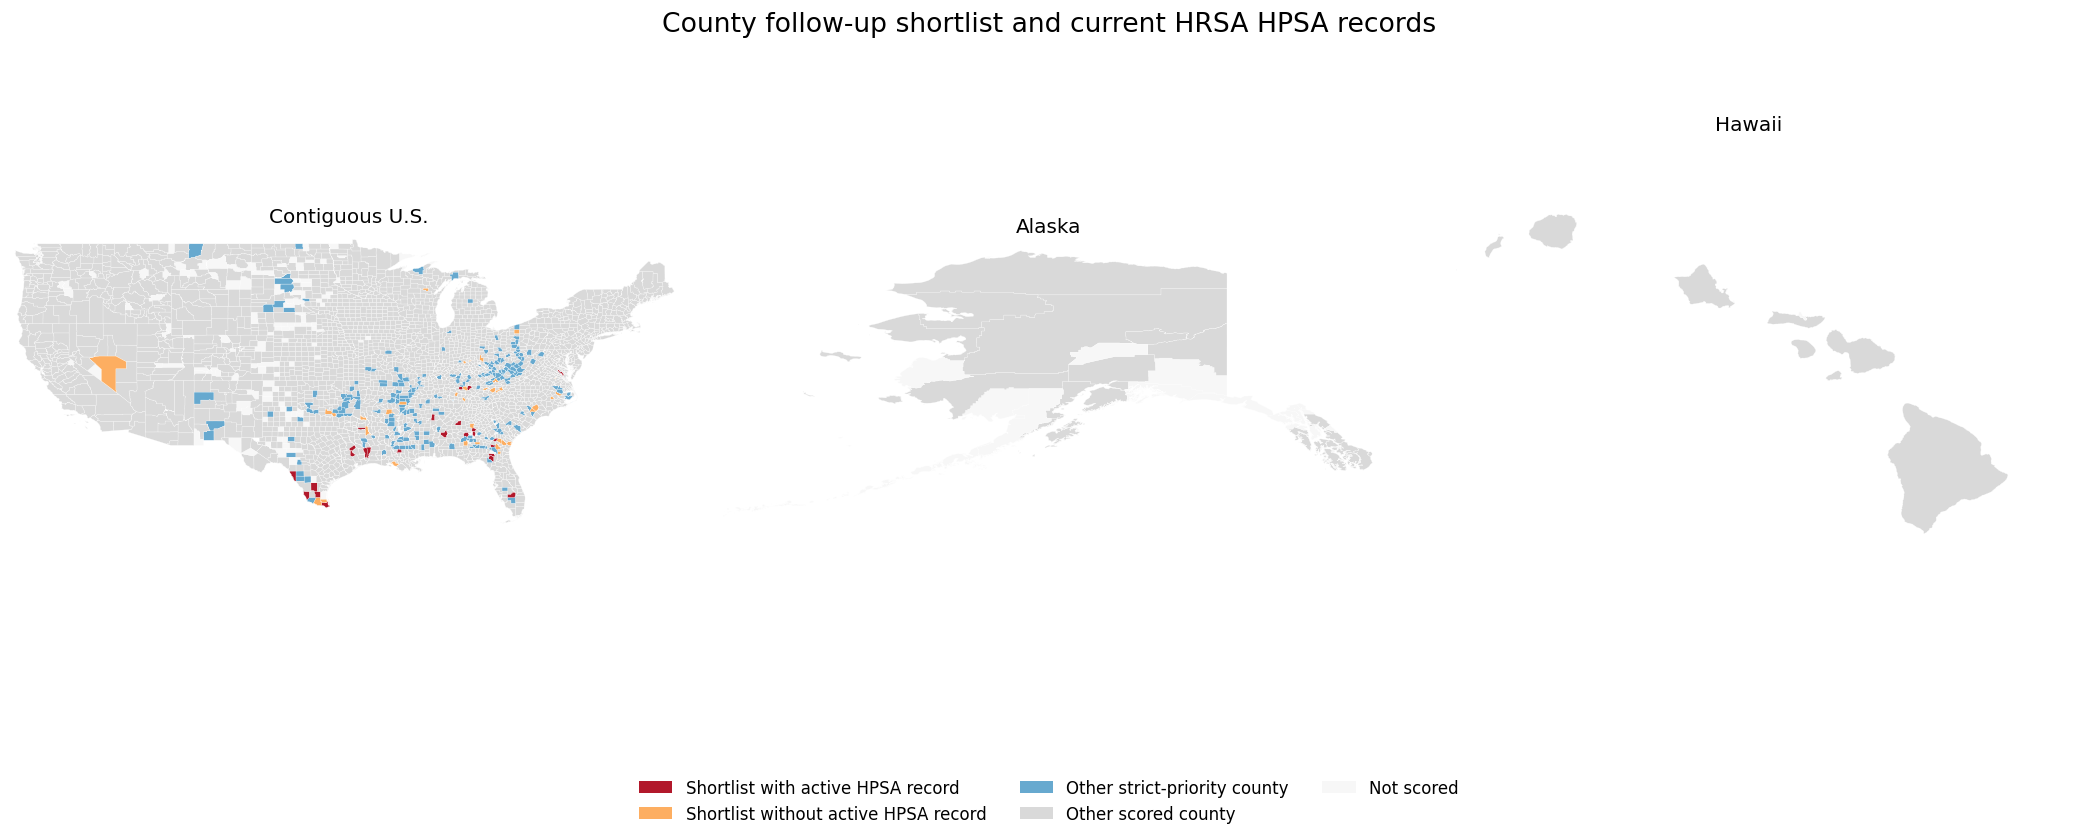

HPSAMapGroup
Shortlist with active HPSA record         27
Shortlist without active HPSA record      36
Other strict-priority county             224
Other scored county                     2710
Not scored                               145
Name: Counties, dtype: int64

,2024 need/readmission quadrant,Counties,With current geographic primary-care HPSA,Share with designation (%)
0,High need / higher readmissions,850,255,30.0
1,High need / lower readmissions,649,209,32.2
2,Lower need / higher readmissions,651,155,23.8
3,Lower need / lower readmissions,847,276,32.6


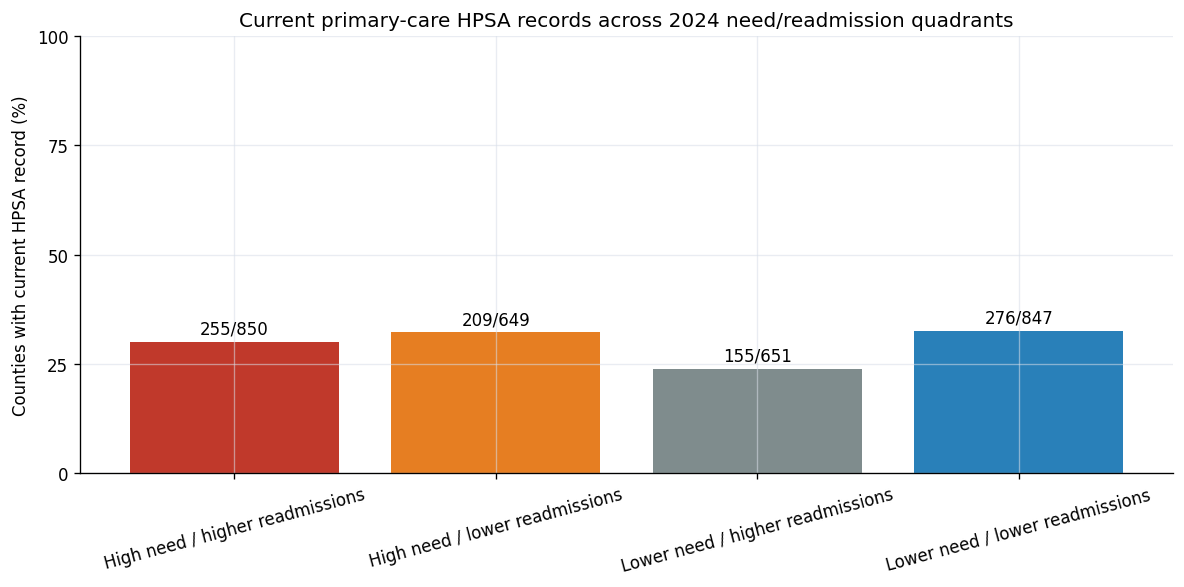

In [21]:
import ssl
from urllib.request import urlopen

import certifi
from IPython.display import display

hpsa_url = "https://data.hrsa.gov/DataDownload/DD_Files/BCD_HPSA_FCT_DET_PC.csv"
hpsa_path = PROJECT_ROOT / "data/raw/hrsa_primary_care_hpsa.csv"
hpsa_path.parent.mkdir(parents=True, exist_ok=True)
if not hpsa_path.exists():
    hpsa_context = ssl.create_default_context(cafile=certifi.where())
    with urlopen(hpsa_url, context=hpsa_context, timeout=120) as response:
        hpsa_path.write_bytes(response.read())

hpsa_columns = [
    "HPSA ID",
    "Designation Type",
    "HPSA Discipline Class",
    "HPSA Status",
    "Common State County FIPS Code",
]
hpsa_data = pd.read_csv(hpsa_path, dtype=str, usecols=hpsa_columns)
geographic_primary_hpsa = hpsa_data.loc[
    hpsa_data["HPSA Discipline Class"].str.strip().eq("Primary Care")
    & hpsa_data["HPSA Status"].str.strip().eq("Designated")
    & hpsa_data["Designation Type"].str.strip().isin(
        ["Geographic HPSA", "High Needs Geographic HPSA"]
    )
].copy()
geographic_primary_hpsa["CountyFIPS"] = (
    geographic_primary_hpsa["Common State County FIPS Code"]
    .str.strip()
    .str.zfill(5)
)
geographic_primary_hpsa = geographic_primary_hpsa.loc[
    geographic_primary_hpsa["CountyFIPS"].str.fullmatch(r"\d{5}", na=False)
    & geographic_primary_hpsa["CountyFIPS"].isin(analysis_df["CountyFIPS"])
]
hpsa_by_county = geographic_primary_hpsa.groupby("CountyFIPS").agg(
    ActivePrimaryCareGeographicHPSARecords=("HPSA ID", "nunique")
)

hpsa_scored = score_df.merge(
    hpsa_by_county,
    left_on="CountyFIPS",
    right_index=True,
    how="left",
    validate="one_to_one",
)
hpsa_scored["ActivePrimaryCareGeographicHPSARecords"] = (
    hpsa_scored["ActivePrimaryCareGeographicHPSARecords"].fillna(0).astype(int)
)
hpsa_scored["HasActivePrimaryCareGeographicHPSA"] = (
    hpsa_scored["ActivePrimaryCareGeographicHPSARecords"].gt(0)
)

hpsa_fqhc_column = "FQHC_RHC_VISITS_PER_1000_BENES"
hpsa_outpatient_column = "OP_VISITS_PER_1000_BENES"
hpsa_fqhc_cutoff = hpsa_scored[hpsa_fqhc_column].median()
hpsa_outpatient_cutoff = hpsa_scored[hpsa_outpatient_column].median()
hpsa_followup_mask = (
    hpsa_scored["StrictPriority"]
    & hpsa_scored[hpsa_fqhc_column].lt(hpsa_fqhc_cutoff)
    & hpsa_scored[hpsa_outpatient_column].lt(hpsa_outpatient_cutoff)
)
hpsa_group_masks = {
    "Follow-up shortlist": hpsa_followup_mask,
    "Other strict-priority counties": hpsa_scored["StrictPriority"] & ~hpsa_followup_mask,
    "Other scored counties": ~hpsa_scored["StrictPriority"],
}
hpsa_profile_rows = []
for label, mask in hpsa_group_masks.items():
    group = hpsa_scored.loc[mask]
    hpsa_count = int(group["HasActivePrimaryCareGeographicHPSA"].sum())
    hpsa_profile_rows.append({
        "County group": label,
        "Counties": len(group),
        "With active geographic primary-care HPSA": hpsa_count,
        "Share with designation (%)": 100 * hpsa_count / len(group) if len(group) else np.nan,
    })
hpsa_profile = pd.DataFrame(hpsa_profile_rows)
print(
    f"Active primary-care geographic HPSA records matched to "
    f"{len(hpsa_by_county):,} counties in the merged project data."
)
display(hpsa_profile.round(1))

fig, ax = plt.subplots(figsize=(9, 5))
hpsa_bar_colors = ["#b2182b", "#ef8a62", "#67a9cf"]
bars = ax.bar(
    hpsa_profile["County group"],
    hpsa_profile["Share with designation (%)"],
    color=hpsa_bar_colors,
)
for bar, (_, row) in zip(bars, hpsa_profile.iterrows()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{int(row['With active geographic primary-care HPSA'])}/{int(row['Counties'])}",
        ha="center",
        va="bottom",
    )
ax.set_ylabel("Counties with active geographic HPSA record (%)")
ax.set_ylim(0, 100)
ax.set_yticks([0, 25, 50, 75, 100])
ax.tick_params(axis="x", labelrotation=15)
ax.set_title("Current primary-care HPSA designation presence by county group")
fig.tight_layout()
plt.show()

from matplotlib.collections import PatchCollection
from matplotlib.patches import Patch, Polygon as MapPolygon

hpsa_scored["FollowUpCandidate"] = hpsa_followup_mask.to_numpy()
hpsa_scored["HPSAMapGroup"] = "Other scored county"
hpsa_scored.loc[hpsa_scored["StrictPriority"], "HPSAMapGroup"] = "Other strict-priority county"
hpsa_scored.loc[
    hpsa_scored["FollowUpCandidate"]
    & hpsa_scored["HasActivePrimaryCareGeographicHPSA"],
    "HPSAMapGroup",
] = "Shortlist with active HPSA record"
hpsa_scored.loc[
    hpsa_scored["FollowUpCandidate"]
    & ~hpsa_scored["HasActivePrimaryCareGeographicHPSA"],
    "HPSAMapGroup",
] = "Shortlist without active HPSA record"
hpsa_map_group_by_fips = hpsa_scored.set_index("CountyFIPS")["HPSAMapGroup"]
hpsa_map_colors = {
    "Shortlist with active HPSA record": "#b2182b",
    "Shortlist without active HPSA record": "#fdae61",
    "Other strict-priority county": "#67a9cf",
    "Other scored county": "#d9d9d9",
    "Not scored": "#f7f7f7",
}
hpsa_map_group_order = list(hpsa_map_colors)

fig, axes = plt.subplots(1, 3, figsize=(18, 7))
for ax, (region, limits) in zip(axes, region_limits.items()):
    patches = []
    facecolors = []
    for vertices, county_fips in region_polygons[region]:
        patches.append(MapPolygon(vertices, closed=True))
        group = hpsa_map_group_by_fips.get(county_fips, "Not scored")
        facecolors.append(hpsa_map_colors[group])

    collection = PatchCollection(
        patches,
        facecolors=facecolors,
        edgecolor="white",
        linewidth=0.15,
    )
    ax.add_collection(collection)
    west, east, south, north = limits
    ax.set_xlim(west, east)
    ax.set_ylim(south, north)
    ax.set_aspect("equal", adjustable="box")
    ax.set_title(region)
    ax.set_axis_off()

hpsa_map_legend = [
    Patch(facecolor=hpsa_map_colors[group], label=group)
    for group in hpsa_map_group_order
]
fig.legend(handles=hpsa_map_legend, loc="lower center", ncol=3, frameon=False)
fig.suptitle("County follow-up shortlist and current HRSA HPSA records", fontsize=16)
fig.subplots_adjust(left=0.02, right=0.98, bottom=0.20, top=0.88, wspace=0.04)
plt.show()

hpsa_map_counts = hpsa_scored["HPSAMapGroup"].value_counts()
hpsa_map_counts.loc["Not scored"] = len(analysis_df) - len(score_df)
display(hpsa_map_counts.reindex(hpsa_map_group_order, fill_value=0).rename("Counties"))

quadrant_order = [
    "High need / higher readmissions",
    "High need / lower readmissions",
    "Lower need / higher readmissions",
    "Lower need / lower readmissions",
]
quadrant_colors_for_hpsa = {
    "High need / higher readmissions": "#c0392b",
    "High need / lower readmissions": "#e67e22",
    "Lower need / higher readmissions": "#7f8c8d",
    "Lower need / lower readmissions": "#2980b9",
}
hpsa_quadrant_rows = []
for quadrant in quadrant_order:
    group = hpsa_scored.loc[hpsa_scored["Quadrant"] == quadrant]
    designated = int(group["HasActivePrimaryCareGeographicHPSA"].sum())
    hpsa_quadrant_rows.append({
        "2024 need/readmission quadrant": quadrant,
        "Counties": len(group),
        "With current geographic primary-care HPSA": designated,
        "Share with designation (%)": 100 * designated / len(group) if len(group) else np.nan,
    })
hpsa_quadrant_profile = pd.DataFrame(hpsa_quadrant_rows)
display(hpsa_quadrant_profile.round(1))

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(
    hpsa_quadrant_profile["2024 need/readmission quadrant"],
    hpsa_quadrant_profile["Share with designation (%)"],
    color=[quadrant_colors_for_hpsa[q] for q in quadrant_order],
)
for bar, (_, row) in zip(bars, hpsa_quadrant_profile.iterrows()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{int(row['With current geographic primary-care HPSA'])}/{int(row['Counties'])}",
        ha="center",
        va="bottom",
    )
ax.set_ylabel("Counties with current HPSA record (%)")
ax.set_ylim(0, 100)
ax.set_yticks([0, 25, 50, 75, 100])
ax.tick_params(axis="x", labelrotation=15)
ax.set_title("Current primary-care HPSA records across 2024 need/readmission quadrants")
fig.tight_layout()
plt.show()

In [22]:
followup_fqhc_column = "FQHC_RHC_VISITS_PER_1000_BENES"
followup_outpatient_column = "OP_VISITS_PER_1000_BENES"
followup_cutoffs = score_df[
    [followup_fqhc_column, followup_outpatient_column]
].median()
followup_mask = (
    score_df["StrictPriority"]
    & score_df[followup_fqhc_column].lt(followup_cutoffs[followup_fqhc_column])
    & score_df[followup_outpatient_column].lt(followup_cutoffs[followup_outpatient_column])
)
followup_counties = score_df.loc[followup_mask].copy()
print(
    f"Exploratory follow-up counties: {len(followup_counties)} of "
    f"{int(score_df['StrictPriority'].sum())} strict-priority counties."
)
print(
    f"Below-median cutoffs: FQHC/RHC = {followup_cutoffs[followup_fqhc_column]:,.1f}; "
    f"outpatient = {followup_cutoffs[followup_outpatient_column]:,.1f} visits per 1,000 beneficiaries."
)
followup_counties.sort_values("NeedScore", ascending=False)[
    [
        "StateAbbr", "CountyName", "CountyFIPS", "BENES_TOTAL_CNT", "NeedScore",
        "ACUTE_HOSP_READMSN_PCT", followup_fqhc_column, followup_outpatient_column,
    ]
].head(15).round(3)

Exploratory follow-up counties: 63 of 287 strict-priority counties.
Below-median cutoffs: FQHC/RHC = 980.8; outpatient = 5,561.2 visits per 1,000 beneficiaries.


,StateAbbr,CountyName,CountyFIPS,BENES_TOTAL_CNT,NeedScore,ACUTE_HOSP_READMSN_PCT,FQHC_RHC_VISITS_PER_1000_BENES,OP_VISITS_PER_1000_BENES
164,AR,St. Francis,05123,5303.0,5.703,0.210,966.701,3919.875
389,GA,Atkinson,13003,1566.0,5.349,0.202,713.235,4857.843
2453,TN,Fentress,47049,6318.0,5.320,0.193,271.092,2666.449
2698,TX,Newton,48351,3108.0,5.295,0.201,724.374,3747.153
53,AL,Dallas,01047,10288.0,5.243,0.203,356.444,3087.556
2775,TX,Zapata,48505,2210.0,4.945,0.299,941.767,2473.896
2176,OK,Marshall,40095,4431.0,4.687,0.199,846.798,4338.217
2472,TN,Jackson,47087,3295.0,4.680,0.218,796.781,3371.563
2841,VA,Emporia,51595,1344.0,4.675,0.216,305.221,3341.366
343,FL,Hamilton,12047,3575.0,4.560,0.198,394.238,2473.844


## Test sensitivity to the follow-up shortlist cutoffs

The 63-county follow-up shortlist uses below-median FQHC/RHC and outpatient visit rates within the strict top-quartile group. To see how much that choice affects membership, this grid varies each indicator's cutoff independently across the 25th, 50th, and 75th percentiles of all scored counties. The table reports each candidate count, how many baseline counties remain, and Jaccard similarity (intersection divided by union) with the median/median shortlist. The 50th/50th cell should reproduce the baseline exactly. Percentile cutoffs are exploratory thresholds, not standards for adequate care.

,FQHC/RHC cutoff percentile,Outpatient cutoff percentile,FQHC/RHC cutoff,Outpatient cutoff,Candidate counties,Baseline counties retained,Baseline retained (%),Jaccard similarity
0,25,25,253.25,4057.13,10,10,15.87,0.16
1,25,50,253.25,5561.21,14,14,22.22,0.22
2,25,75,253.25,7400.96,17,14,22.22,0.21
3,50,25,980.75,4057.13,41,41,65.08,0.65
4,50,50,980.75,5561.21,63,63,100.00,1.00
5,50,75,980.75,7400.96,75,63,100.00,0.84
6,75,25,2300.27,4057.13,75,41,65.08,0.42
7,75,50,2300.27,5561.21,140,63,100.00,0.45
8,75,75,2300.27,7400.96,164,63,100.00,0.38


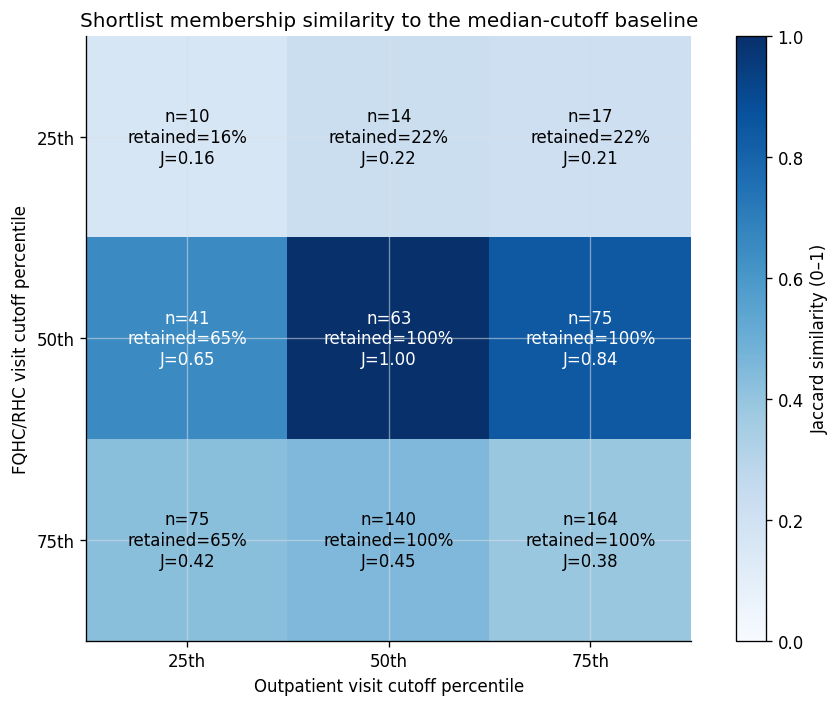

In [23]:
service_cutoff_percentiles = [25, 50, 75]
service_thresholds = {
    followup_fqhc_column: score_df[followup_fqhc_column].quantile(
        [p / 100 for p in service_cutoff_percentiles]
    ),
    followup_outpatient_column: score_df[followup_outpatient_column].quantile(
        [p / 100 for p in service_cutoff_percentiles]
    ),
}
baseline_followup_fips = set(score_df.loc[followup_mask, "CountyFIPS"])
service_sensitivity_rows = []
service_sensitivity_counts = np.zeros(
    (len(service_cutoff_percentiles), len(service_cutoff_percentiles)),
    dtype=int,
)
service_sensitivity_jaccard = np.zeros_like(
    service_sensitivity_counts,
    dtype=float,
)
for row_index, fqhc_percentile in enumerate(service_cutoff_percentiles):
    for column_index, outpatient_percentile in enumerate(service_cutoff_percentiles):
        candidate_mask = (
            score_df["StrictPriority"]
            & score_df[followup_fqhc_column].lt(
                service_thresholds[followup_fqhc_column].loc[fqhc_percentile / 100]
            )
            & score_df[followup_outpatient_column].lt(
                service_thresholds[followup_outpatient_column].loc[outpatient_percentile / 100]
            )
        )
        candidate_fips = set(score_df.loc[candidate_mask, "CountyFIPS"])
        intersection_count = len(candidate_fips & baseline_followup_fips)
        union_count = len(candidate_fips | baseline_followup_fips)
        jaccard = intersection_count / union_count if union_count else np.nan
        service_sensitivity_counts[row_index, column_index] = len(candidate_fips)
        service_sensitivity_jaccard[row_index, column_index] = jaccard
        service_sensitivity_rows.append({
            "FQHC/RHC cutoff percentile": fqhc_percentile,
            "Outpatient cutoff percentile": outpatient_percentile,
            "FQHC/RHC cutoff": service_thresholds[followup_fqhc_column].loc[
                fqhc_percentile / 100
            ],
            "Outpatient cutoff": service_thresholds[followup_outpatient_column].loc[
                outpatient_percentile / 100
            ],
            "Candidate counties": len(candidate_fips),
            "Baseline counties retained": intersection_count,
            "Baseline retained (%)": (
                100 * intersection_count / len(baseline_followup_fips)
                if baseline_followup_fips else np.nan
            ),
            "Jaccard similarity": jaccard,
        })

service_sensitivity_profile = pd.DataFrame(service_sensitivity_rows)
baseline_check = service_sensitivity_profile.loc[
    service_sensitivity_profile["FQHC/RHC cutoff percentile"].eq(50)
    & service_sensitivity_profile["Outpatient cutoff percentile"].eq(50)
].iloc[0]
if int(baseline_check["Candidate counties"]) != len(baseline_followup_fips):
    raise ValueError("The 50th/50th percentile cell does not reproduce the baseline shortlist.")
if int(baseline_check["Baseline counties retained"]) != len(baseline_followup_fips):
    raise ValueError("The 50th/50th percentile cell does not retain every baseline county.")
display(service_sensitivity_profile.round(2))

fig, ax = plt.subplots(figsize=(8, 6))
heatmap = ax.imshow(service_sensitivity_jaccard, cmap="Blues", vmin=0, vmax=1)
percentile_labels = [f"{p}th" for p in service_cutoff_percentiles]
ax.set_xticks(range(len(percentile_labels)), percentile_labels)
ax.set_yticks(range(len(percentile_labels)), percentile_labels)
ax.set_xlabel("Outpatient visit cutoff percentile")
ax.set_ylabel("FQHC/RHC visit cutoff percentile")
ax.set_title("Shortlist membership similarity to the median-cutoff baseline")
for row_index in range(len(service_cutoff_percentiles)):
    for column_index in range(len(service_cutoff_percentiles)):
        profile_row = service_sensitivity_profile.iloc[
            row_index * len(service_cutoff_percentiles) + column_index
        ]
        ax.text(
            column_index,
            row_index,
            f"n={int(profile_row['Candidate counties'])}\n"
            f"retained={profile_row['Baseline retained (%)']:.0f}%\n"
            f"J={profile_row['Jaccard similarity']:.2f}",
            ha="center",
            va="center",
            color="white" if profile_row["Jaccard similarity"] > 0.55 else "black",
        )
fig.colorbar(heatmap, ax=ax, label="Jaccard similarity (0–1)")
fig.tight_layout()
plt.show()

## Identify counties consistently selected across cutoffs

The grid above shows group-level overlap. This section counts, for each strict-priority county, how many of the nine cutoff combinations include it. A county selected in all nine combinations is in the shortlist even at the strictest tested thresholds (25th percentile for both indicators). This frequency summarizes robustness to this particular grid; it is not a probability, quality rating, or additional ranking.

In [24]:
scenario_membership = pd.DataFrame(index=score_df.index)
for fqhc_percentile in service_cutoff_percentiles:
    for outpatient_percentile in service_cutoff_percentiles:
        scenario_name = f"FQHC {fqhc_percentile}th / outpatient {outpatient_percentile}th"
        scenario_membership[scenario_name] = (
            score_df["StrictPriority"]
            & score_df[followup_fqhc_column].lt(
                service_thresholds[followup_fqhc_column].loc[fqhc_percentile / 100]
            )
            & score_df[followup_outpatient_column].lt(
                service_thresholds[followup_outpatient_column].loc[outpatient_percentile / 100]
            )
        )

county_scenario_count = scenario_membership.sum(axis=1).astype(int)
strict_scenario_counts = county_scenario_count.loc[score_df["StrictPriority"]]
scenario_count_distribution = (
    strict_scenario_counts.value_counts()
    .reindex(range(len(service_cutoff_percentiles) ** 2 + 1), fill_value=0)
    .rename_axis("Number of cutoff scenarios selected")
    .rename("Strict-priority counties")
    .to_frame()
)
scenario_count_distribution["Share of strict-priority counties (%)"] = (
    100 * scenario_count_distribution["Strict-priority counties"]
    / len(strict_scenario_counts)
)
display(scenario_count_distribution.round(1))

stable_counties = score_df.loc[
    score_df["StrictPriority"] & county_scenario_count.eq(
        len(service_cutoff_percentiles) ** 2
    )
].copy()
if set(stable_counties["CountyFIPS"]) != set(
    score_df.loc[
        score_df["StrictPriority"]
        & score_df[followup_fqhc_column].lt(
            service_thresholds[followup_fqhc_column].loc[0.25]
        )
        & score_df[followup_outpatient_column].lt(
            service_thresholds[followup_outpatient_column].loc[0.25]
        ),
        "CountyFIPS",
    ]
):
    raise ValueError("All-scenario counties do not match the strictest cutoff scenario.")
print(
    f"Counties selected in all nine tested cutoff combinations: "
    f"{len(stable_counties)} of {int(score_df['StrictPriority'].sum())} strict-priority counties."
)
display(
    stable_counties.sort_values("NeedScore", ascending=False)[
        [
            "StateAbbr", "CountyName", "CountyFIPS", "NeedScore",
            followup_fqhc_column, followup_outpatient_column, "BENES_TOTAL_CNT",
        ]
    ].round(2)
)

,Strict-priority counties,Share of strict-priority counties (%)
Number of cutoff scenarios selected,,
0,123,42.9
1,12,4.2
2,52,18.1
3,37,12.9
4,18,6.3
5,0,0.0
6,35,12.2
7,0,0.0
8,0,0.0


Counties selected in all nine tested cutoff combinations: 10 of 287 strict-priority counties.


,StateAbbr,CountyName,CountyFIPS,NeedScore,FQHC_RHC_VISITS_PER_1000_BENES,OP_VISITS_PER_1000_BENES,BENES_TOTAL_CNT
2867,VA,Hopewell,51670,4.06,123.81,3168.41,5323.0
2438,TN,Carter,47019,3.93,196.83,2711.18,15576.0
2458,TN,Greene,47059,3.71,151.95,3633.43,21288.0
2899,VA,Petersburg,51730,3.58,166.01,3354.58,9615.0
535,GA,Ware,13299,3.23,203.48,3013.20,8862.0
2726,TX,San Jacinto,48407,3.12,199.82,2766.06,6984.0
538,GA,Wayne,13305,3.04,131.23,3157.81,6604.0
1977,NV,Nye,32023,2.98,121.86,964.10,18955.0
1694,NC,Greene,37079,2.95,204.66,2014.25,4111.0
2631,TX,Hidalgo,48215,2.92,80.31,3330.53,124582.0


In [25]:
share_fqhc_column = "FQHC_RHC_VISITS_PER_1000_BENES"
share_outpatient_column = "OP_VISITS_PER_1000_BENES"
share_pattern_labels = [
    "Below both medians",
    "FQHC/RHC below; outpatient at/above",
    "FQHC/RHC at/above; outpatient below",
    "At/above both medians",
]
share_pattern_colors = ["#762a83", "#af8dc3", "#7fbf7b", "#1b7837"]
share_cutoffs = score_df[[share_fqhc_column, share_outpatient_column]].median()
share_df = score_df.dropna(
    subset=[share_fqhc_column, share_outpatient_column]
).copy()
share_conditions = [
    share_df[share_fqhc_column].lt(share_cutoffs[share_fqhc_column])
    & share_df[share_outpatient_column].lt(share_cutoffs[share_outpatient_column]),
    share_df[share_fqhc_column].lt(share_cutoffs[share_fqhc_column])
    & share_df[share_outpatient_column].ge(share_cutoffs[share_outpatient_column]),
    share_df[share_fqhc_column].ge(share_cutoffs[share_fqhc_column])
    & share_df[share_outpatient_column].lt(share_cutoffs[share_outpatient_column]),
]
share_df["ServiceUsePattern"] = np.select(
    share_conditions,
    share_pattern_labels[:3],
    default=share_pattern_labels[3],
)

pattern_counts = pd.crosstab(
    share_df["PriorityTier"],
    share_df["ServiceUsePattern"],
).reindex(
    index=priority_tier_order,
    columns=share_pattern_labels,
    fill_value=0,
)
pattern_shares = pattern_counts.div(pattern_counts.sum(axis=1), axis=0) * 100

pattern_summary_rows = []
for tier in priority_tier_order:
    tier_total = int(pattern_counts.loc[tier].sum())
    for pattern in share_pattern_labels:
        count = int(pattern_counts.loc[tier, pattern])
        pattern_summary_rows.append({
            "Priority tier": tier,
            "Service-use pattern": pattern,
            "Count": count,
            "Tier total": tier_total,
            "Share within tier (%)": pattern_shares.loc[tier, pattern],
        })
pattern_summary = pd.DataFrame(pattern_summary_rows)
pattern_summary.round(1)

,Priority tier,Service-use pattern,Count,Tier total,Share within tier (%)
0,Strict priority,Below both medians,63,285,22.1
1,Strict priority,FQHC/RHC below; outpatient at/above,29,285,10.2
2,Strict priority,FQHC/RHC at/above; outpatient below,127,285,44.6
3,Strict priority,At/above both medians,66,285,23.2
4,"Median priority, not strict",Below both medians,171,562,30.4
5,"Median priority, not strict",FQHC/RHC below; outpatient at/above,84,562,14.9
6,"Median priority, not strict",FQHC/RHC at/above; outpatient below,151,562,26.9
7,"Median priority, not strict",At/above both medians,156,562,27.8
8,Other counties,Below both medians,667,2137,31.2
9,Other counties,FQHC/RHC below; outpatient at/above,478,2137,22.4


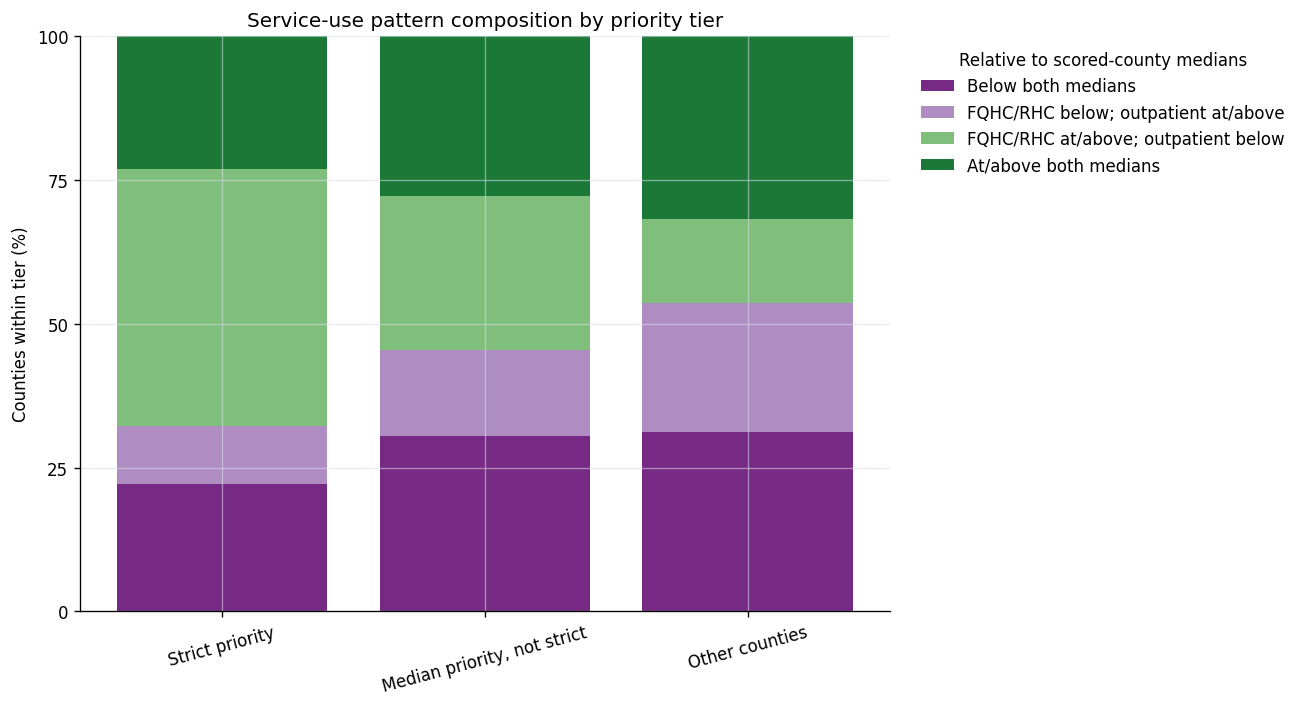

In [26]:
fig, ax = plt.subplots(figsize=(11, 6))
bottom = np.zeros(len(priority_tier_order))
for pattern, color in zip(share_pattern_labels, share_pattern_colors):
    shares = pattern_shares.loc[priority_tier_order, pattern].to_numpy()
    ax.bar(
        priority_tier_order,
        shares,
        bottom=bottom,
        color=color,
        label=pattern,
    )
    bottom += shares
ax.set_ylabel("Counties within tier (%)")
ax.set_ylim(0, 100)
ax.set_yticks([0, 25, 50, 75, 100])
ax.tick_params(axis="x", labelrotation=15)
ax.set_title("Service-use pattern composition by priority tier")
ax.legend(title="Relative to scored-county medians", frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
plt.show()

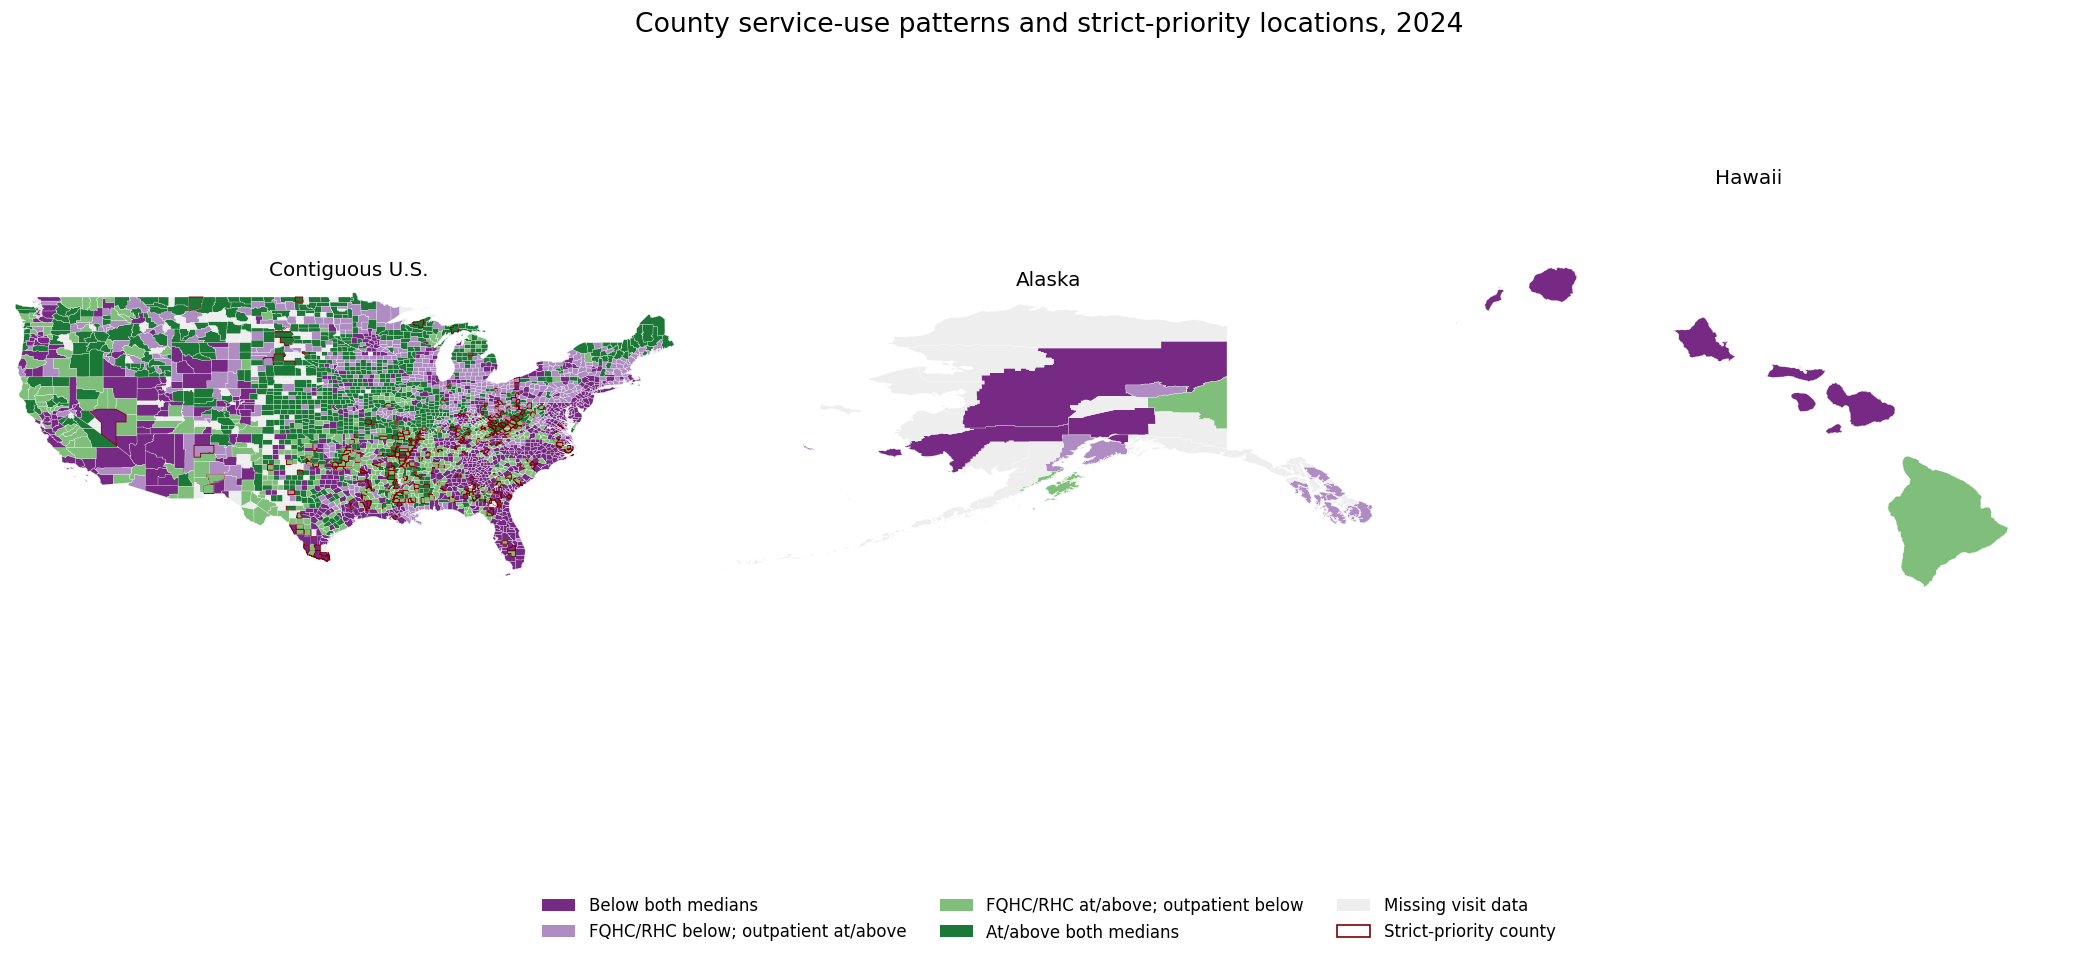

Counties mapped by service-use pattern: 2,984
ServiceUsePattern            Below both medians  \
PriorityTier                                      
Strict priority                              63   
Median priority, not strict                 171   
Other counties                              667   

ServiceUsePattern            FQHC/RHC below; outpatient at/above  \
PriorityTier                                                       
Strict priority                                               29   
Median priority, not strict                                   84   
Other counties                                               478   

ServiceUsePattern            FQHC/RHC at/above; outpatient below  \
PriorityTier                                                       
Strict priority                                              127   
Median priority, not strict                                  151   
Other counties                                               314   

ServiceUsePatter

In [27]:
fqhc_column = "FQHC_RHC_VISITS_PER_1000_BENES"
outpatient_column = "OP_VISITS_PER_1000_BENES"
service_map_cutoffs = score_df[[fqhc_column, outpatient_column]].median()
service_map_df = score_df.dropna(
    subset=[fqhc_column, outpatient_column]
).copy()

service_pattern_labels = [
    "Below both medians",
    "FQHC/RHC below; outpatient at/above",
    "FQHC/RHC at/above; outpatient below",
    "At/above both medians",
]
service_conditions = [
    service_map_df[fqhc_column].lt(service_map_cutoffs[fqhc_column])
    & service_map_df[outpatient_column].lt(service_map_cutoffs[outpatient_column]),
    service_map_df[fqhc_column].lt(service_map_cutoffs[fqhc_column])
    & service_map_df[outpatient_column].ge(service_map_cutoffs[outpatient_column]),
    service_map_df[fqhc_column].ge(service_map_cutoffs[fqhc_column])
    & service_map_df[outpatient_column].lt(service_map_cutoffs[outpatient_column]),
]
service_map_df["ServiceUsePattern"] = np.select(
    service_conditions,
    service_pattern_labels[:3],
    default=service_pattern_labels[3],
)
service_pattern_colors = {
    "Below both medians": "#762a83",
    "FQHC/RHC below; outpatient at/above": "#af8dc3",
    "FQHC/RHC at/above; outpatient below": "#7fbf7b",
    "At/above both medians": "#1b7837",
    "Missing visit data": "#eeeeee",
}
service_pattern_by_fips = service_map_df.set_index("CountyFIPS")["ServiceUsePattern"]

fig, axes = plt.subplots(1, 3, figsize=(18, 8))
for ax, (region, limits) in zip(axes, region_limits.items()):
    patches = []
    facecolors = []
    edge_colors = []
    line_widths = []
    for vertices, county_fips in region_polygons[region]:
        patches.append(MapPolygon(vertices, closed=True))
        pattern = service_pattern_by_fips.get(county_fips, "Missing visit data")
        facecolors.append(service_pattern_colors[pattern])
        if county_fips in strict_priority_fips:
            edge_colors.append("#7f0000")
            line_widths.append(0.55)
        else:
            edge_colors.append("white")
            line_widths.append(0.15)

    collection = PatchCollection(
        patches,
        facecolors=facecolors,
        edgecolor=edge_colors,
        linewidth=line_widths,
    )
    ax.add_collection(collection)
    west, east, south, north = limits
    ax.set_xlim(west, east)
    ax.set_ylim(south, north)
    ax.set_aspect("equal", adjustable="box")
    ax.set_title(region)
    ax.set_axis_off()

service_map_legend = [
    Patch(facecolor=service_pattern_colors[label], label=label)
    for label in service_pattern_labels
]
service_map_legend.append(
    Patch(facecolor=service_pattern_colors["Missing visit data"], label="Missing visit data")
)
service_map_legend.append(
    Patch(facecolor="none", edgecolor="#7f0000", label="Strict-priority county")
)
fig.legend(
    handles=service_map_legend,
    loc="lower center",
    ncol=3,
    frameon=False,
)
fig.suptitle("County service-use patterns and strict-priority locations, 2024", fontsize=16)
fig.subplots_adjust(left=0.02, right=0.98, bottom=0.20, top=0.88, wspace=0.04)
plt.show()

print(f"Counties mapped by service-use pattern: {len(service_map_df):,}")
print(
    service_map_df.groupby(["PriorityTier", "ServiceUsePattern"], observed=True)
    .size()
    .unstack(fill_value=0)
    .reindex(index=priority_tier_order, columns=service_pattern_labels, fill_value=0)
)

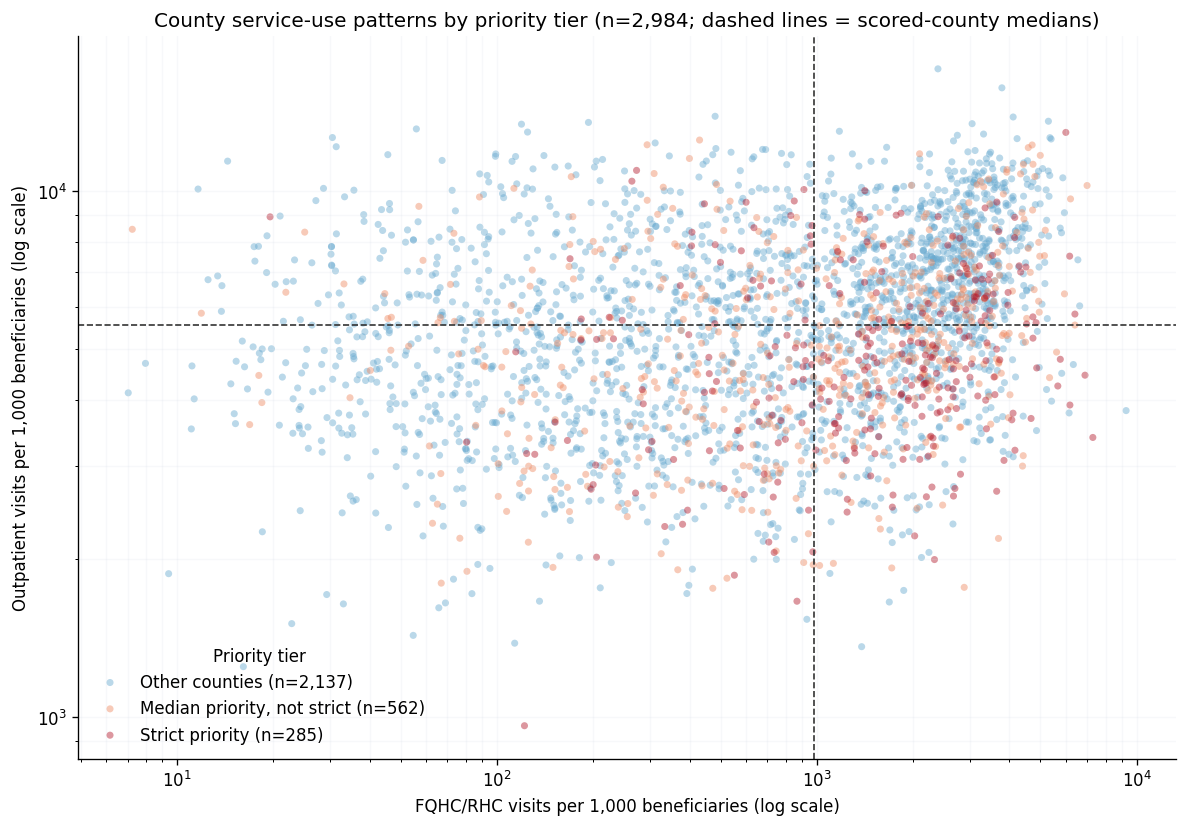

Counties shown with both visit rates: 2,984


In [28]:
fqhc_column = "FQHC_RHC_VISITS_PER_1000_BENES"
outpatient_column = "OP_VISITS_PER_1000_BENES"
scatter_cutoffs = score_df[[fqhc_column, outpatient_column]].median()
service_scatter_df = score_df.dropna(
    subset=[fqhc_column, outpatient_column]
)
scatter_tier_order = [
    "Other counties",
    "Median priority, not strict",
    "Strict priority",
]
tier_colors = {
    "Strict priority": "#b2182b",
    "Median priority, not strict": "#ef8a62",
    "Other counties": "#67a9cf",
}

fig, ax = plt.subplots(figsize=(10, 7))
for tier in scatter_tier_order:
    group = service_scatter_df.loc[service_scatter_df["PriorityTier"] == tier]
    ax.scatter(
        group[fqhc_column],
        group[outpatient_column],
        s=18,
        alpha=0.45,
        color=tier_colors[tier],
        edgecolors="none",
        label=f"{tier} (n={len(group):,})",
    )

ax.axvline(
    scatter_cutoffs[fqhc_column],
    color="#333333",
    linestyle="--",
    linewidth=1,
)
ax.axhline(
    scatter_cutoffs[outpatient_column],
    color="#333333",
    linestyle="--",
    linewidth=1,
)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("FQHC/RHC visits per 1,000 beneficiaries (log scale)")
ax.set_ylabel("Outpatient visits per 1,000 beneficiaries (log scale)")
ax.set_title(
    f"County service-use patterns by priority tier "
    f"(n={len(service_scatter_df):,}; dashed lines = scored-county medians)"
)
ax.legend(title="Priority tier", frameon=False)
ax.grid(alpha=0.2, which="both")
fig.tight_layout()
plt.show()
print(f"Counties shown with both visit rates: {len(service_scatter_df):,}")

In [29]:
sensitivity_indicators = {
    "FQHC_RHC_VISITS_PER_1000_BENES": "FQHC/RHC visits per 1,000 beneficiaries",
    "OP_VISITS_PER_1000_BENES": "Outpatient visits per 1,000 beneficiaries",
}
sensitivity_cutoffs = score_df[list(sensitivity_indicators)].median()
denominator_sensitivity_rows = []
county_size_scenarios = {
    "All scored counties": set(),
    "Exclude bottom total-beneficiary quartile": total_bottom,
    "Exclude bottom Original Medicare quartile": om_bottom,
}
for scenario, excluded_counties in county_size_scenarios.items():
    retained_df = score_df.loc[~score_df.index.isin(excluded_counties)]
    for tier in priority_tier_order:
        tier_rows = retained_df.loc[retained_df["PriorityTier"] == tier]
        full_tier_rows = score_df.loc[score_df["PriorityTier"] == tier]
        for column, label in sensitivity_indicators.items():
            values = tier_rows[column].dropna()
            full_values = full_tier_rows[column].dropna()
            below_count = int(values.lt(sensitivity_cutoffs[column]).sum())
            full_below_count = int(full_values.lt(sensitivity_cutoffs[column]).sum())
            full_below_pct = (
                100 * full_below_count / len(full_values) if len(full_values) else np.nan
            )
            below_pct = 100 * below_count / len(values) if len(values) else np.nan
            denominator_sensitivity_rows.append({
                "County-size scenario": scenario,
                "Priority tier": tier,
                "Indicator": label,
                "Full-sample count": len(full_values),
                "Full-sample below median (%)": full_below_pct,
                "Count after scenario": len(values),
                "Below median count": below_count,
                "Below median (%)": below_pct,
                "Change (percentage points)": below_pct - full_below_pct,
            })

denominator_sensitivity_profile = pd.DataFrame(denominator_sensitivity_rows)
display(denominator_sensitivity_profile.head(12).round(2))
print(
    f"Excluded {len(total_bottom):,} counties using total-beneficiary counts and "
    f"{len(om_bottom):,} using Original Medicare beneficiary counts. "
    "Rate-specific CMS denominators have not been independently confirmed here."
)
denominator_sensitivity_profile.round(2)

,County-size scenario,Priority tier,Indicator,Full-sample count,Full-sample below median (%),Count after scenario,Below median count,Below median (%),Change (percentage points)
0,All scored counties,Strict priority,"FQHC/RHC visits per 1,000 beneficiaries",285,32.28,285,92,32.28,0.00
1,All scored counties,Strict priority,"Outpatient visits per 1,000 beneficiaries",287,66.55,287,191,66.55,0.00
2,All scored counties,"Median priority, not strict","FQHC/RHC visits per 1,000 beneficiaries",562,45.37,562,255,45.37,0.00
3,All scored counties,"Median priority, not strict","Outpatient visits per 1,000 beneficiaries",563,57.19,563,322,57.19,0.00
4,All scored counties,Other counties,"FQHC/RHC visits per 1,000 beneficiaries",2137,53.58,2137,1145,53.58,0.00
5,All scored counties,Other counties,"Outpatient visits per 1,000 beneficiaries",2147,45.88,2147,985,45.88,0.00
6,Exclude bottom total-beneficiary quartile,Strict priority,"FQHC/RHC visits per 1,000 beneficiaries",285,32.28,183,70,38.25,5.97
7,Exclude bottom total-beneficiary quartile,Strict priority,"Outpatient visits per 1,000 beneficiaries",287,66.55,183,124,67.76,1.21
8,Exclude bottom total-beneficiary quartile,"Median priority, not strict","FQHC/RHC visits per 1,000 beneficiaries",562,45.37,453,237,52.32,6.94
9,Exclude bottom total-beneficiary quartile,"Median priority, not strict","Outpatient visits per 1,000 beneficiaries",563,57.19,453,272,60.04,2.85


Excluded 750 counties using total-beneficiary counts and 750 using Original Medicare beneficiary counts. Rate-specific CMS denominators have not been independently confirmed here.


,County-size scenario,Priority tier,Indicator,Full-sample count,Full-sample below median (%),Count after scenario,Below median count,Below median (%),Change (percentage points)
0,All scored counties,Strict priority,"FQHC/RHC visits per 1,000 beneficiaries",285,32.28,285,92,32.28,0.00
1,All scored counties,Strict priority,"Outpatient visits per 1,000 beneficiaries",287,66.55,287,191,66.55,0.00
2,All scored counties,"Median priority, not strict","FQHC/RHC visits per 1,000 beneficiaries",562,45.37,562,255,45.37,0.00
3,All scored counties,"Median priority, not strict","Outpatient visits per 1,000 beneficiaries",563,57.19,563,322,57.19,0.00
4,All scored counties,Other counties,"FQHC/RHC visits per 1,000 beneficiaries",2137,53.58,2137,1145,53.58,0.00
5,All scored counties,Other counties,"Outpatient visits per 1,000 beneficiaries",2147,45.88,2147,985,45.88,0.00
6,Exclude bottom total-beneficiary quartile,Strict priority,"FQHC/RHC visits per 1,000 beneficiaries",285,32.28,183,70,38.25,5.97
7,Exclude bottom total-beneficiary quartile,Strict priority,"Outpatient visits per 1,000 beneficiaries",287,66.55,183,124,67.76,1.21
8,Exclude bottom total-beneficiary quartile,"Median priority, not strict","FQHC/RHC visits per 1,000 beneficiaries",562,45.37,453,237,52.32,6.94
9,Exclude bottom total-beneficiary quartile,"Median priority, not strict","Outpatient visits per 1,000 beneficiaries",563,57.19,453,272,60.04,2.85


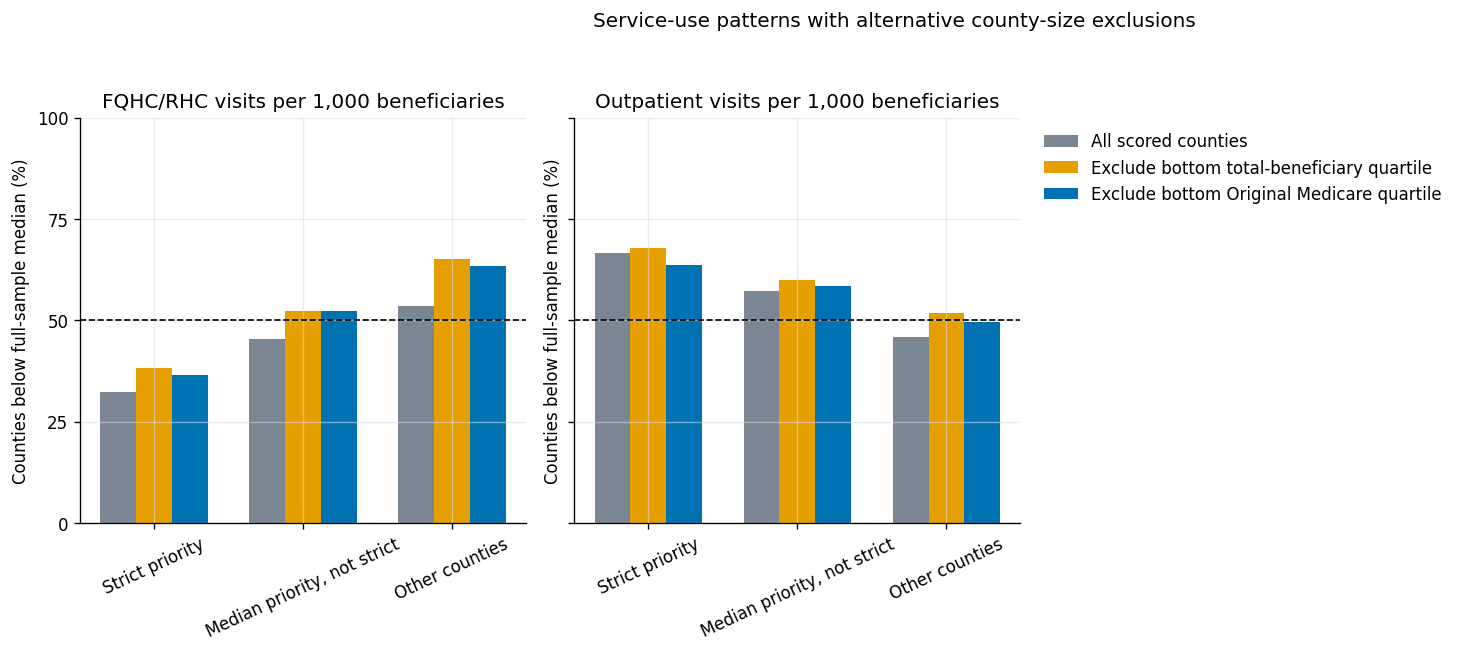

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
x = np.arange(len(priority_tier_order))
bar_width = 0.24
scenario_colors = [PALETTE["gray"], PALETTE["orange"], PALETTE["blue"]]
for ax, (column, label) in zip(axes, sensitivity_indicators.items()):
    for scenario_index, (scenario, color) in enumerate(
        zip(county_size_scenarios, scenario_colors)
    ):
        sensitivity = denominator_sensitivity_profile.loc[
            denominator_sensitivity_profile["Indicator"].eq(label)
            & denominator_sensitivity_profile["County-size scenario"].eq(scenario)
        ].set_index("Priority tier").reindex(priority_tier_order)
        ax.bar(
            x + (scenario_index - 1) * bar_width,
            sensitivity["Below median (%)"],
            width=bar_width,
            color=color,
            label=scenario,
        )
    ax.axhline(50, color="black", linestyle="--", linewidth=1)
    ax.set_title(label)
    ax.set_ylabel("Counties below full-sample median (%)")
    ax.set_ylim(0, 100)
    ax.set_yticks([0, 25, 50, 75, 100])
    ax.set_xticks(x)
    ax.set_xticklabels(priority_tier_order, rotation=25)
axes[1].legend(frameon=False, loc="upper left", bbox_to_anchor=(1.02, 1))
fig.suptitle("Service-use patterns with alternative county-size exclusions")
fig.tight_layout(rect=(0, 0, 0.82, 0.94))
plt.show()

In [31]:
below_median_rows = []
service_use_labels = {
    "FQHC_RHC_VISITS_PER_1000_BENES": "FQHC/RHC visits per 1,000 beneficiaries",
    "OP_VISITS_PER_1000_BENES": "Outpatient visits per 1,000 beneficiaries",
}
service_use_cutoffs = score_df[list(service_use_labels)].median()

for tier in priority_tier_order:
    tier_rows = score_df.loc[score_df["PriorityTier"] == tier]
    for column, label in service_use_labels.items():
        values = tier_rows[column].dropna()
        below_count = int(values.lt(service_use_cutoffs[column]).sum())
        below_median_rows.append({
            "Priority tier": tier,
            "Indicator": label,
            "Scored-county median": service_use_cutoffs[column],
            "Count with data": len(values),
            "Count below median": below_count,
            "Below median (%)": 100 * below_count / len(values) if len(values) else np.nan,
        })

below_median_profile = pd.DataFrame(below_median_rows)
below_median_profile.round(2)

,Priority tier,Indicator,Scored-county median,Count with data,Count below median,Below median (%)
0,Strict priority,"FQHC/RHC visits per 1,000 beneficiaries",980.75,285,92,32.28
1,Strict priority,"Outpatient visits per 1,000 beneficiaries",5561.21,287,191,66.55
2,"Median priority, not strict","FQHC/RHC visits per 1,000 beneficiaries",980.75,562,255,45.37
3,"Median priority, not strict","Outpatient visits per 1,000 beneficiaries",5561.21,563,322,57.19
4,Other counties,"FQHC/RHC visits per 1,000 beneficiaries",980.75,2137,1145,53.58
5,Other counties,"Outpatient visits per 1,000 beneficiaries",5561.21,2147,985,45.88


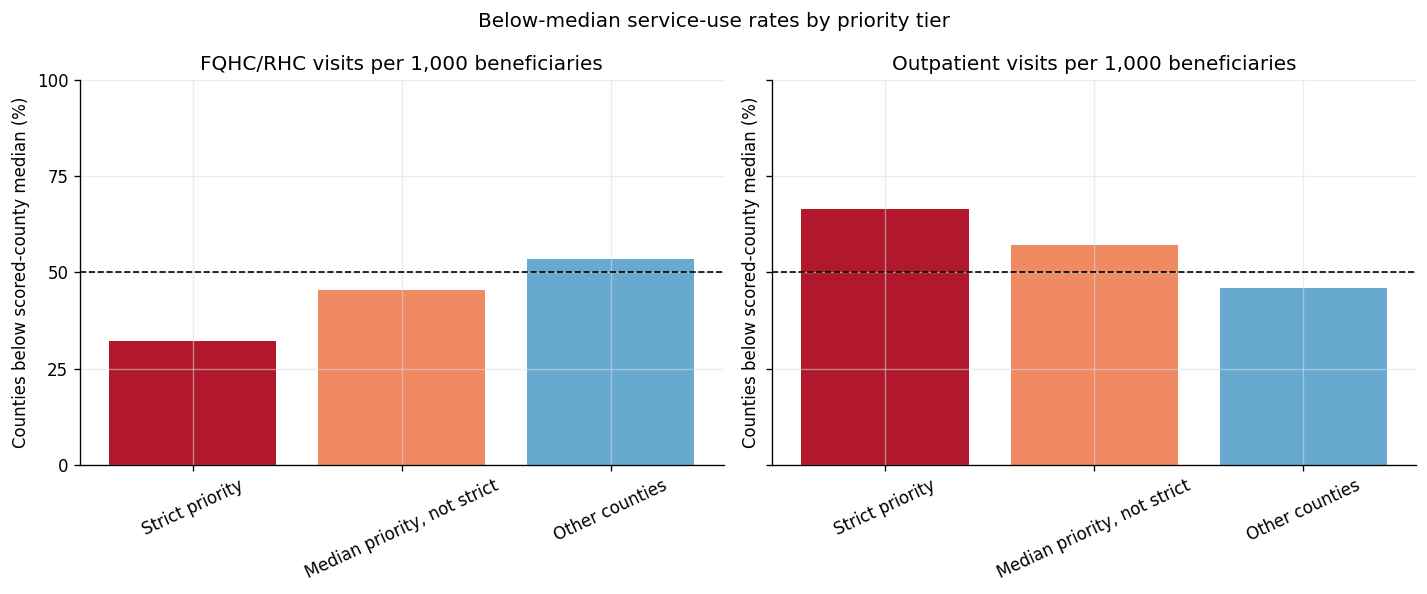

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, (column, label) in zip(axes, service_use_labels.items()):
    plot_data = below_median_profile.loc[
        below_median_profile["Indicator"] == label
    ].set_index("Priority tier").reindex(priority_tier_order)
    ax.bar(
        priority_tier_order,
        plot_data["Below median (%)"],
        color=["#b2182b", "#ef8a62", "#67a9cf"],
    )
    ax.axhline(50, color="black", linestyle="--", linewidth=1)
    ax.set_title(label)
    ax.set_ylabel("Counties below scored-county median (%)")
    ax.set_ylim(0, 100)
    ax.set_yticks([0, 25, 50, 75, 100])
    ax.tick_params(axis="x", labelrotation=25)
fig.suptitle("Below-median service-use rates by priority tier")
fig.tight_layout()
plt.show()

## Add a closer-to-2024 primary-care supply measure

The [HRSA AHRF 2024–2025 county file](https://data.hrsa.gov/DataDownload/AHRF/AHRF_2024-2025_CSV.zip) includes `phys_nf_prim_care_pc_exc_rsdt_23`: non-federal primary-care physicians in patient care, excluding hospital residents and physicians age 75 or older (AMA Physician Master File, 2023 count). The denominator, `popn_est_24`, is the 2024 Census county population estimate. This section calculates physicians per 100,000 residents, compares the follow-up shortlist with other scored counties, and maps the rate. The numerator is from 2023, so this is close to—but not an exact—2024 supply measure. Physician density is a supply proxy; it does not capture within-county distribution, appointment availability, or all primary-care clinicians.

Overall scored-county median: 44.48 primary-care physicians per 100,000 residents.


,County group,Count with data,"Median physicians per 100,000",25th percentile,75th percentile,Below overall median (%)
0,Follow-up shortlist,63,25.80,15.49,47.03,73.02
1,Other strict-priority counties,224,29.82,16.03,45.87,74.55
2,Other scored counties,2701,46.19,28.12,71.30,47.43


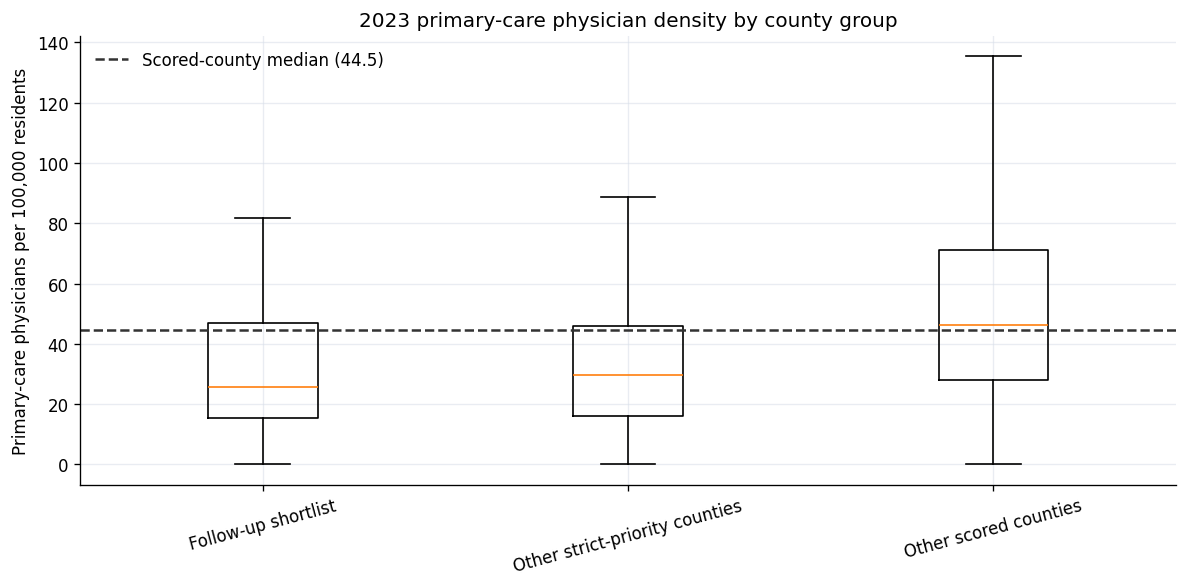

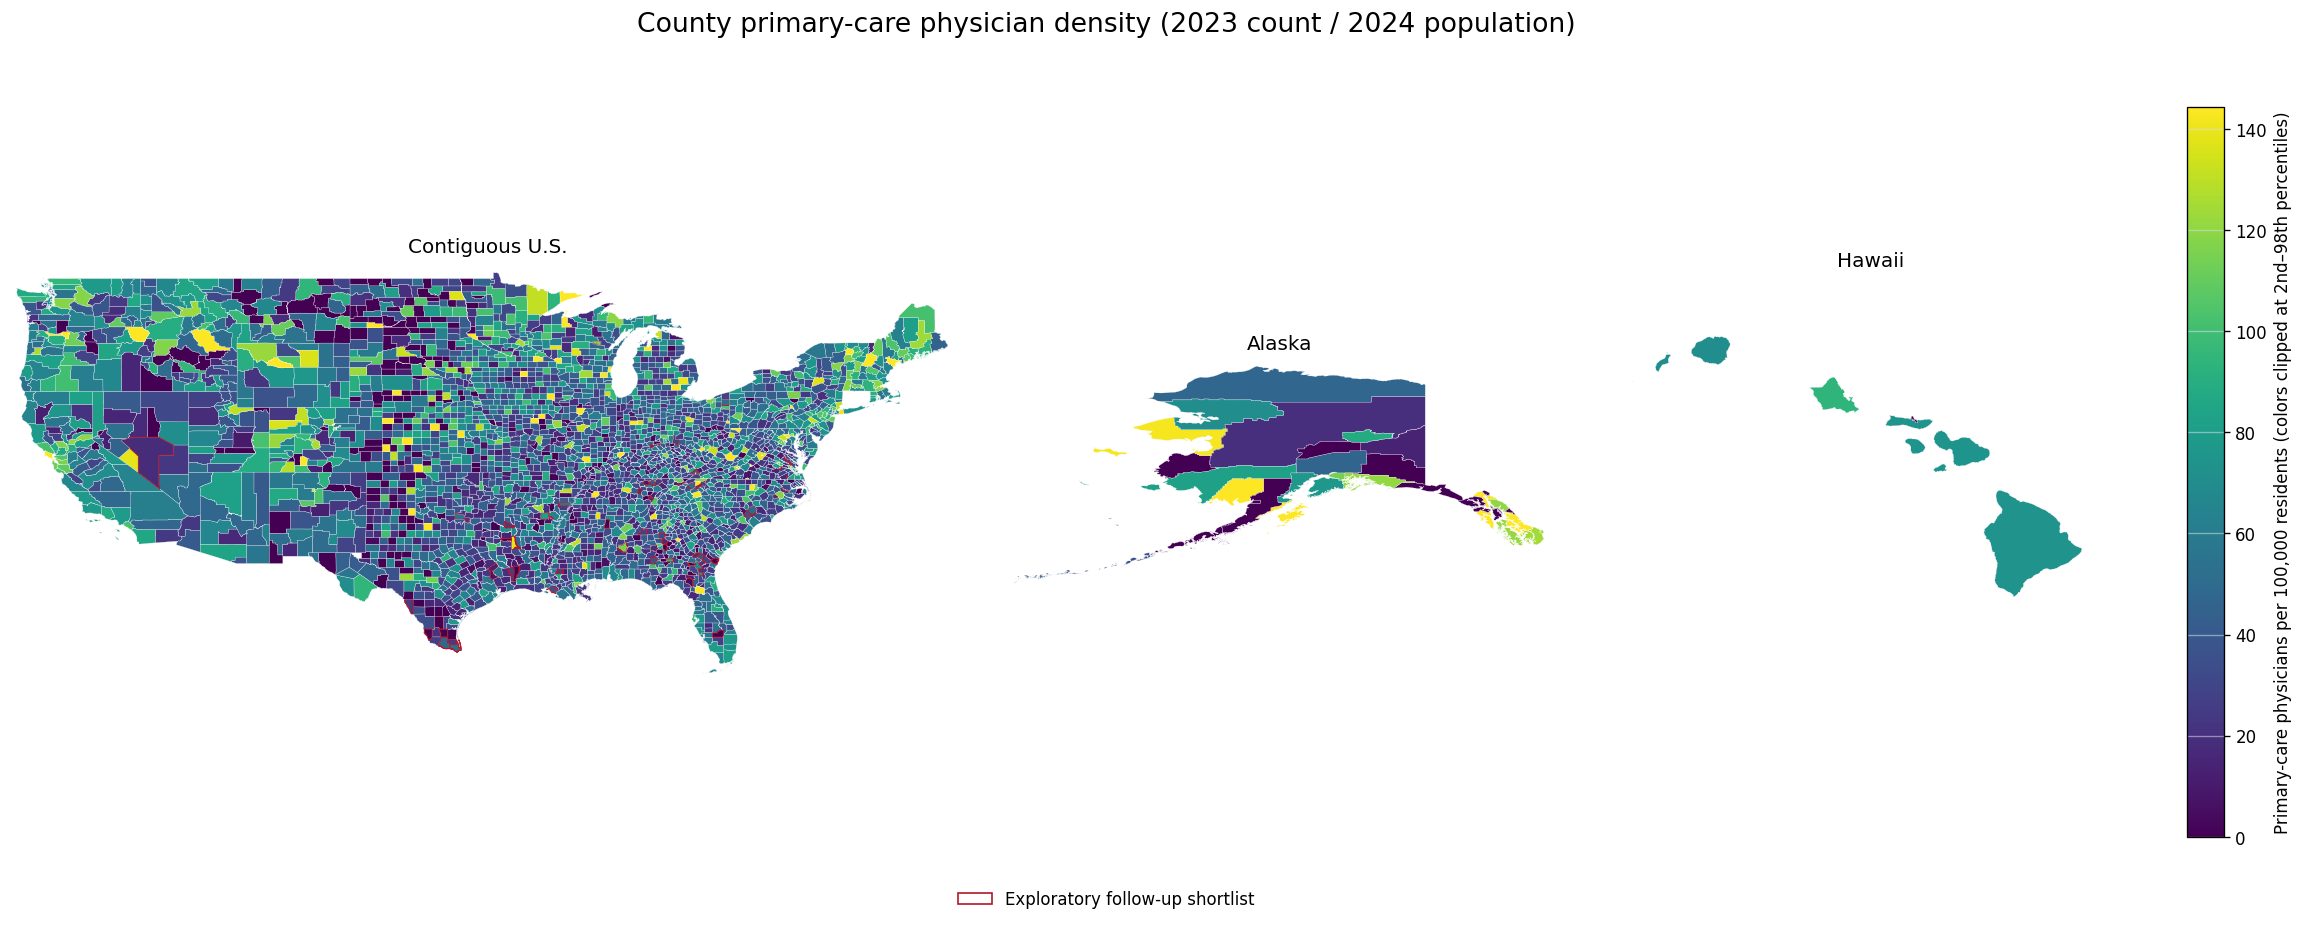

Scored counties with AHRF physician density: 2,988 of 2,997
Follow-up counties with AHRF physician density: 63 of 63


In [33]:
import ssl
import zipfile
from urllib.request import urlopen

import certifi
from IPython.display import display
from matplotlib.cm import ScalarMappable
from matplotlib.collections import PatchCollection
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Polygon as MapPolygon

ahrf_url = "https://data.hrsa.gov/DataDownload/AHRF/AHRF_2024-2025_CSV.zip"
ahrf_path = PROJECT_ROOT / "data/raw/ahrf_2024_2025_county_csv.zip"
ahrf_path.parent.mkdir(parents=True, exist_ok=True)
if not ahrf_path.exists():
    ahrf_context = ssl.create_default_context(cafile=certifi.where())
    with urlopen(ahrf_url, context=ahrf_context, timeout=120) as response:
        ahrf_path.write_bytes(response.read())

with zipfile.ZipFile(ahrf_path) as ahrf_archive:
    hp_member = next(
        name for name in ahrf_archive.namelist()
        if name.endswith("AHRF2025hp.csv")
    )
    pop_member = next(
        name for name in ahrf_archive.namelist()
        if name.endswith("AHRF2025pop.csv")
    )
    ahrf_physicians = pd.read_csv(
        ahrf_archive.open(hp_member),
        dtype={"fips_st_cnty": str},
        usecols=["fips_st_cnty", "phys_nf_prim_care_pc_exc_rsdt_23"],
    )
    ahrf_population = pd.read_csv(
        ahrf_archive.open(pop_member),
        dtype={"fips_st_cnty": str},
        usecols=["fips_st_cnty", "popn_est_24"],
    )

ahrf_county_supply = ahrf_physicians.merge(
    ahrf_population,
    on="fips_st_cnty",
    how="outer",
    validate="one_to_one",
).rename(columns={
    "fips_st_cnty": "CountyFIPS",
    "phys_nf_prim_care_pc_exc_rsdt_23": "PrimaryCarePhysicians2023",
    "popn_est_24": "PopulationEstimate2024",
})
ahrf_county_supply["CountyFIPS"] = ahrf_county_supply["CountyFIPS"].str.zfill(5)
for column in ["PrimaryCarePhysicians2023", "PopulationEstimate2024"]:
    ahrf_county_supply[column] = pd.to_numeric(
        ahrf_county_supply[column], errors="coerce"
    )
ahrf_county_supply["PrimaryCarePhysiciansPer100k"] = (
    ahrf_county_supply["PrimaryCarePhysicians2023"]
    / ahrf_county_supply["PopulationEstimate2024"].where(
        ahrf_county_supply["PopulationEstimate2024"].gt(0)
    )
    * 100_000
)

ahrf_scored = score_df.merge(
    ahrf_county_supply[["CountyFIPS", "PrimaryCarePhysiciansPer100k"]],
    on="CountyFIPS",
    how="left",
    validate="one_to_one",
)
supply_fqhc_column = "FQHC_RHC_VISITS_PER_1000_BENES"
supply_outpatient_column = "OP_VISITS_PER_1000_BENES"
supply_followup_mask = (
    ahrf_scored["StrictPriority"]
    & ahrf_scored[supply_fqhc_column].lt(ahrf_scored[supply_fqhc_column].median())
    & ahrf_scored[supply_outpatient_column].lt(ahrf_scored[supply_outpatient_column].median())
)
supply_group_masks = {
    "Follow-up shortlist": supply_followup_mask,
    "Other strict-priority counties": ahrf_scored["StrictPriority"] & ~supply_followup_mask,
    "Other scored counties": ~ahrf_scored["StrictPriority"],
}
overall_supply_median = ahrf_scored["PrimaryCarePhysiciansPer100k"].median()
supply_profile_rows = []
supply_boxplot_data = []
for label, mask in supply_group_masks.items():
    values = ahrf_scored.loc[mask, "PrimaryCarePhysiciansPer100k"].dropna()
    supply_boxplot_data.append(values)
    below_count = int(values.lt(overall_supply_median).sum())
    supply_profile_rows.append({
        "County group": label,
        "Count with data": len(values),
        "Median physicians per 100,000": values.median(),
        "25th percentile": values.quantile(0.25),
        "75th percentile": values.quantile(0.75),
        "Below overall median (%)": 100 * below_count / len(values) if len(values) else np.nan,
    })
supply_profile = pd.DataFrame(supply_profile_rows)
print(
    f"Overall scored-county median: {overall_supply_median:.2f} primary-care "
    "physicians per 100,000 residents."
)
display(supply_profile.round(2))

fig, ax = plt.subplots(figsize=(10, 5))
ax.boxplot(
    supply_boxplot_data,
    tick_labels=list(supply_group_masks),
    showfliers=False,
)
ax.axhline(
    overall_supply_median,
    color="#333333",
    linestyle="--",
    label=f"Scored-county median ({overall_supply_median:.1f})",
)
ax.set_ylabel("Primary-care physicians per 100,000 residents")
ax.tick_params(axis="x", labelrotation=15)
ax.set_title("2023 primary-care physician density by county group")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

provider_by_fips = ahrf_county_supply.set_index("CountyFIPS")["PrimaryCarePhysiciansPer100k"]
provider_values = provider_by_fips.dropna()
map_lower, map_upper = provider_values.quantile([0.02, 0.98])
provider_norm = Normalize(vmin=map_lower, vmax=map_upper, clip=True)
supply_followup_fips = set(
    ahrf_scored.loc[supply_followup_mask, "CountyFIPS"]
)
fig, axes = plt.subplots(
    1, 4, figsize=(19, 8),
    gridspec_kw={"width_ratios": [1.3, 0.75, 0.75, 0.05]},
)
for ax, (region, limits) in zip(axes[:3], region_limits.items()):
    patches = []
    patch_values = []
    edge_colors = []
    line_widths = []
    for vertices, county_fips in region_polygons[region]:
        value = provider_by_fips.get(county_fips)
        if pd.notna(value):
            patches.append(MapPolygon(vertices, closed=True))
            patch_values.append(value)
            is_followup = county_fips in supply_followup_fips
            edge_colors.append("#b2182b" if is_followup else "white")
            line_widths.append(0.55 if is_followup else 0.15)

    collection = PatchCollection(
        patches,
        cmap="viridis",
        norm=provider_norm,
        edgecolor=edge_colors,
        linewidth=line_widths,
    )
    collection.set_array(np.asarray(patch_values))
    ax.add_collection(collection)
    west, east, south, north = limits
    ax.set_xlim(west, east)
    ax.set_ylim(south, north)
    ax.set_aspect("equal", adjustable="box")
    ax.set_title(region)
    ax.set_axis_off()

provider_colorbar = fig.colorbar(
    ScalarMappable(norm=provider_norm, cmap="viridis"),
    cax=axes[3],
)
provider_colorbar.set_label(
    "Primary-care physicians per 100,000 residents "
    "(colors clipped at 2nd–98th percentiles)"
)
fig.legend(
    handles=[Patch(facecolor="none", edgecolor="#b2182b", label="Exploratory follow-up shortlist")],
    loc="lower center",
    bbox_to_anchor=(0.5, 0.03),
    frameon=False,
)
fig.suptitle("County primary-care physician density (2023 count / 2024 population)", fontsize=16)
fig.subplots_adjust(left=0.02, right=0.99, bottom=0.12, top=0.88, wspace=0.08)
plt.show()

print(f"Scored counties with AHRF physician density: {ahrf_scored['PrimaryCarePhysiciansPer100k'].notna().sum():,} of {len(ahrf_scored):,}")
print(f"Follow-up counties with AHRF physician density: {ahrf_scored.loc[supply_followup_mask, 'PrimaryCarePhysiciansPer100k'].notna().sum():,} of {int(supply_followup_mask.sum())}")

## Triangulate provider-supply signals for follow-up

This comparison checks whether exploratory follow-up counties also have (1) below-median AHRF primary-care physician density and/or (2) a current county-linked HRSA geographic primary-care HPSA record. These are complementary but imperfect signals: the physician rate uses a 2023 count and 2024 population, while HPSA is a current snapshot. The table and chart are descriptive; they do not create a composite score or establish that a county lacks access. “Neither signal observed” means neither flag is present—not that access is adequate. An HPSA record may cover only part of a county.

,County group,Counties,With AHRF density,AHRF density unavailable,Below-median density + HPSA record (n),Below-median density + HPSA record (%),Below-median density only (n),Below-median density only (%),HPSA record only (n),HPSA record only (%),Neither signal observed (n),Neither signal observed (%)
0,Follow-up shortlist,63,63,0,24,38.1,22,34.9,3,4.8,14,22.2
1,Other strict-priority counties,224,224,0,66,29.5,101,45.1,10,4.5,47,21.0
2,Other scored counties,2710,2701,9,506,18.7,775,28.7,284,10.5,1136,42.1


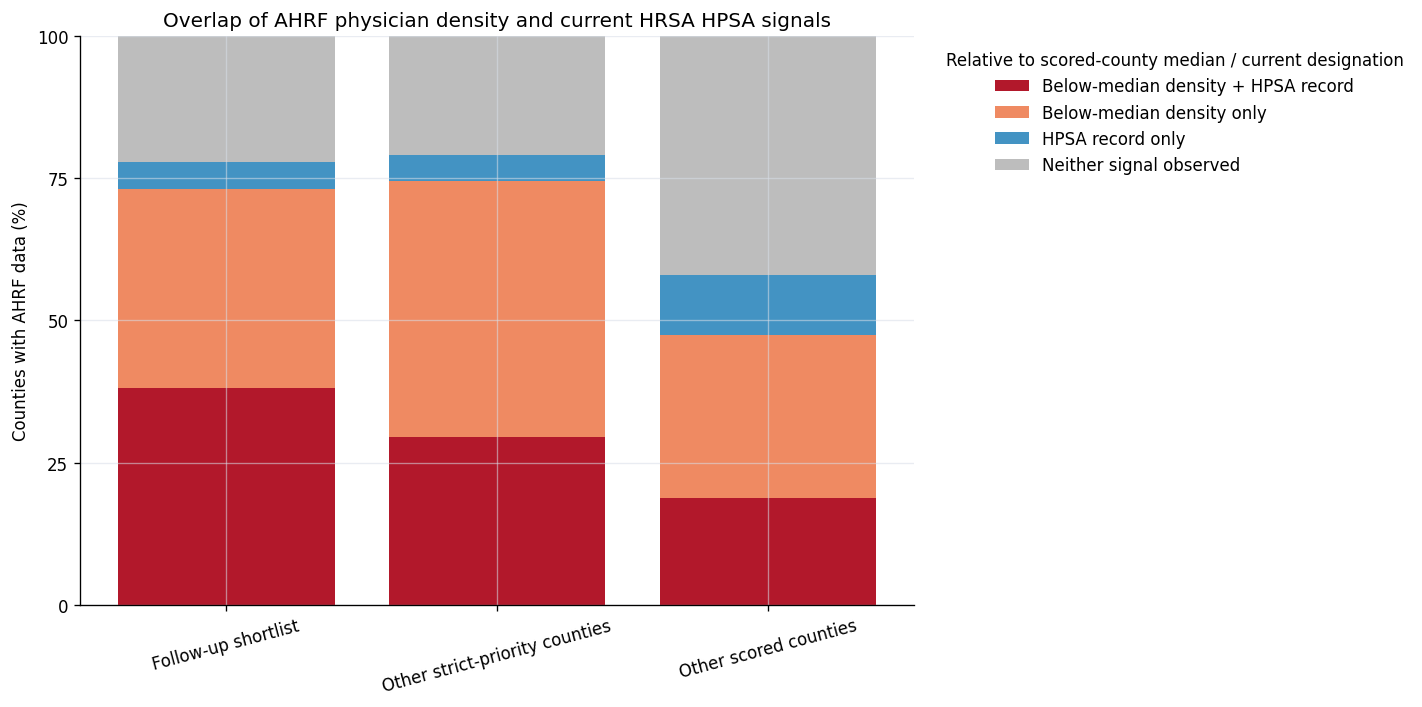

Follow-up shortlist counties with both contextual signals: 24 of 63.


,StateAbbr,CountyName,CountyFIPS,NeedScore,PrimaryCarePhysiciansPer100k,ActivePrimaryCareGeographicHPSARecords,FQHC_RHC_VISITS_PER_1000_BENES,OP_VISITS_PER_1000_BENES,BENES_TOTAL_CNT
363,GA,Atkinson,13003,5.35,0.00,1,713.24,4857.84,1566.0
2341,TN,Fentress,47049,5.32,24.84,1,271.09,2666.45,6318.0
2566,TX,Newton,48351,5.30,0.00,1,724.37,3747.15,3108.0
2637,TX,Zapata,48505,4.94,0.00,1,941.77,2473.90,2210.0
2360,TN,Jackson,47087,4.68,8.08,1,796.78,3371.56,3295.0
2698,VA,Emporia,51595,4.68,0.00,1,305.22,3341.37,1344.0
317,FL,Hamilton,12047,4.56,13.95,1,394.24,2473.84,3575.0
2469,TX,Duval,48131,3.99,0.00,1,735.20,2056.07,2514.0
2517,TX,Jasper,48241,3.93,27.35,1,660.03,3644.30,9378.0
2552,TX,Maverick,48323,3.89,25.50,1,970.97,2061.80,11609.0


In [34]:
triangulated_scored = ahrf_scored.merge(
    hpsa_scored[[
        "CountyFIPS", "HasActivePrimaryCareGeographicHPSA",
        "ActivePrimaryCareGeographicHPSARecords",
    ]],
    on="CountyFIPS",
    how="left",
    validate="one_to_one",
)
if triangulated_scored["HasActivePrimaryCareGeographicHPSA"].isna().any():
    raise ValueError("Some scored counties are missing the HRSA county-level HPSA flag.")

triangulated_scored["FollowUpCandidate"] = (
    triangulated_scored["StrictPriority"]
    & triangulated_scored[supply_fqhc_column].lt(
        score_df[supply_fqhc_column].median()
    )
    & triangulated_scored[supply_outpatient_column].lt(
        score_df[supply_outpatient_column].median()
    )
)
triangulated_scored["BelowMedianPhysicianDensity"] = (
    triangulated_scored["PrimaryCarePhysiciansPer100k"].lt(overall_supply_median)
)
triangulation_patterns = [
    "Below-median density + HPSA record",
    "Below-median density only",
    "HPSA record only",
    "Neither signal observed",
]
has_density = triangulated_scored["PrimaryCarePhysiciansPer100k"].notna()
low_density = triangulated_scored["BelowMedianPhysicianDensity"]
has_hpsa = triangulated_scored["HasActivePrimaryCareGeographicHPSA"]
triangulated_scored["ProviderSignalPattern"] = np.select(
    [
        has_density & low_density & has_hpsa,
        has_density & low_density & ~has_hpsa,
        has_density & ~low_density & has_hpsa,
        has_density & ~low_density & ~has_hpsa,
    ],
    triangulation_patterns,
    default="AHRF density unavailable",
)
triangulation_group_masks = {
    "Follow-up shortlist": triangulated_scored["FollowUpCandidate"],
    "Other strict-priority counties": (
        triangulated_scored["StrictPriority"]
        & ~triangulated_scored["FollowUpCandidate"]
    ),
    "Other scored counties": ~triangulated_scored["StrictPriority"],
}

triangulation_rows = []
for group_label, group_mask in triangulation_group_masks.items():
    group = triangulated_scored.loc[group_mask]
    valid_group = group.loc[group["PrimaryCarePhysiciansPer100k"].notna()]
    row = {
        "County group": group_label,
        "Counties": len(group),
        "With AHRF density": len(valid_group),
        "AHRF density unavailable": len(group) - len(valid_group),
    }
    for pattern in triangulation_patterns:
        count = int(valid_group["ProviderSignalPattern"].eq(pattern).sum())
        row[f"{pattern} (n)"] = count
        row[f"{pattern} (%)"] = (
            100 * count / len(valid_group) if len(valid_group) else np.nan
        )
    triangulation_rows.append(row)
triangulation_profile = pd.DataFrame(triangulation_rows)
display(triangulation_profile.round(1))

pattern_colors = ["#b2182b", "#ef8a62", "#4393c3", "#bdbdbd"]
fig, ax = plt.subplots(figsize=(12, 6))
bottom = np.zeros(len(triangulation_profile))
for pattern, color in zip(triangulation_patterns, pattern_colors):
    shares = triangulation_profile[f"{pattern} (%)"].fillna(0).to_numpy()
    ax.bar(
        triangulation_profile["County group"],
        shares,
        bottom=bottom,
        color=color,
        label=pattern,
    )
    bottom += shares
ax.set_ylabel("Counties with AHRF data (%)")
ax.set_ylim(0, 100)
ax.set_yticks([0, 25, 50, 75, 100])
ax.tick_params(axis="x", labelrotation=15)
ax.set_title("Overlap of AHRF physician density and current HRSA HPSA signals")
ax.legend(title="Relative to scored-county median / current designation", frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
plt.show()

both_signal_followup = triangulated_scored.loc[
    triangulated_scored["FollowUpCandidate"]
    & triangulated_scored["ProviderSignalPattern"].eq(
        "Below-median density + HPSA record"
    )
].sort_values("NeedScore", ascending=False)
print(
    f"Follow-up shortlist counties with both contextual signals: "
    f"{len(both_signal_followup)} of {int(triangulated_scored['FollowUpCandidate'].sum())}."
)
display(both_signal_followup[
    [
        "StateAbbr", "CountyName", "CountyFIPS", "NeedScore",
        "PrimaryCarePhysiciansPer100k", "ActivePrimaryCareGeographicHPSARecords",
        supply_fqhc_column, supply_outpatient_column, "BENES_TOTAL_CNT",
    ]
].round(2))

## Check sensitivity to the physician-density cutoff

The earlier overlap used the scored-county median to flag low AHRF physician density. Because that cutoff is a choice, this check repeats the comparison at the 25th, 50th, and 75th percentiles of scored-county density. For each county group, it reports how many fall below each cutoff and how many also have a current geographic primary-care HPSA record. Percentiles use counties with observed AHRF density; ties can make the share below a cutoff differ from the nominal percentile. This is a robustness check, not a new county designation.

,Density cutoff,"Cutoff (physicians per 100,000)",County group,Count with density,Below cutoff (n),Below cutoff (%),Below cutoff + HPSA (n),With both signals (% of group),HPSA among below cutoff (%)
0,25th percentile,26.39,Follow-up shortlist,63,33,52.38,21,33.33,63.64
1,25th percentile,26.39,Other strict-priority counties,224,99,44.20,53,23.66,53.54
2,25th percentile,26.39,Other scored counties,2701,615,22.77,302,11.18,49.11
3,50th percentile (median),44.48,Follow-up shortlist,63,46,73.02,24,38.10,52.17
4,50th percentile (median),44.48,Other strict-priority counties,224,167,74.55,66,29.46,39.52
5,50th percentile (median),44.48,Other scored counties,2701,1281,47.43,506,18.73,39.50
6,75th percentile,69.00,Follow-up shortlist,63,56,88.89,25,39.68,44.64
7,75th percentile,69.00,Other strict-priority counties,224,205,91.52,74,33.04,36.10
8,75th percentile,69.00,Other scored counties,2701,1980,73.31,663,24.55,33.48


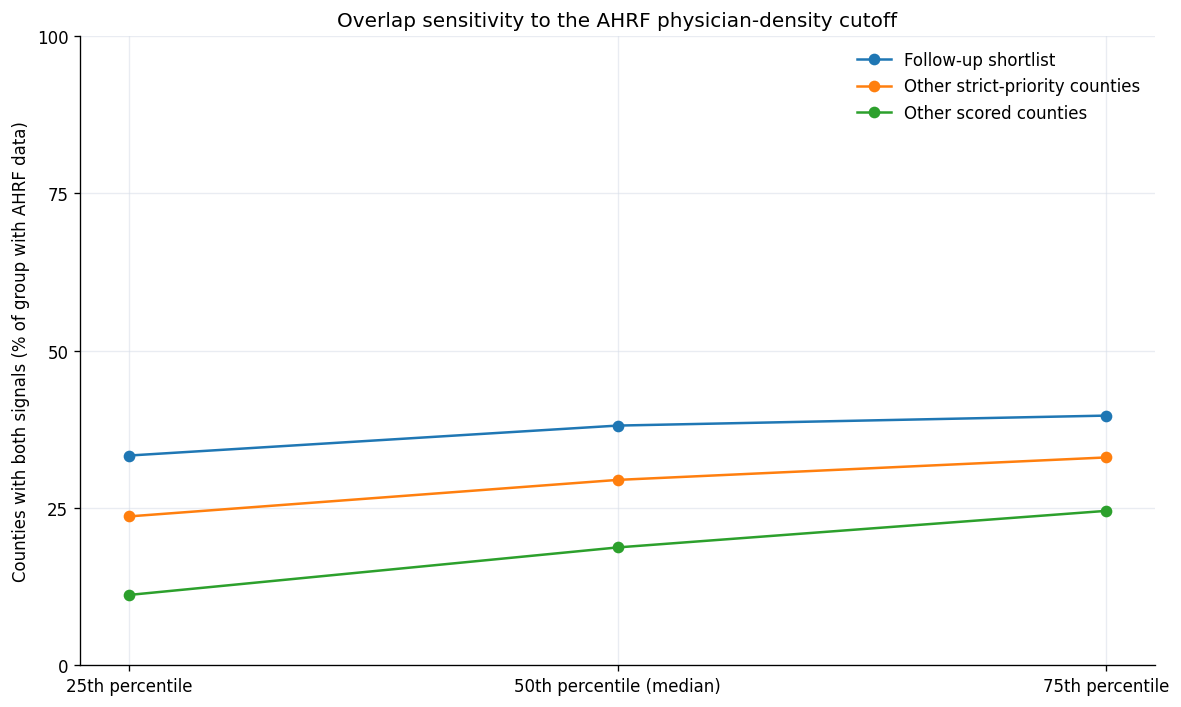

In [35]:
density_quantiles = ahrf_scored["PrimaryCarePhysiciansPer100k"].dropna().quantile(
    [0.25, 0.50, 0.75]
)
density_thresholds = [
    ("25th percentile", float(density_quantiles.loc[0.25])),
    ("50th percentile (median)", float(density_quantiles.loc[0.50])),
    ("75th percentile", float(density_quantiles.loc[0.75])),
]
density_sensitivity_rows = []
for threshold_label, threshold_value in density_thresholds:
    for group_label, group_mask in triangulation_group_masks.items():
        group = triangulated_scored.loc[group_mask]
        valid_group = group.loc[group["PrimaryCarePhysiciansPer100k"].notna()]
        below_cutoff = valid_group["PrimaryCarePhysiciansPer100k"].lt(threshold_value)
        below_and_hpsa = (
            below_cutoff
            & valid_group["HasActivePrimaryCareGeographicHPSA"]
        )
        below_count = int(below_cutoff.sum())
        both_count = int(below_and_hpsa.sum())
        density_sensitivity_rows.append({
            "Density cutoff": threshold_label,
            "Cutoff (physicians per 100,000)": threshold_value,
            "County group": group_label,
            "Count with density": len(valid_group),
            "Below cutoff (n)": below_count,
            "Below cutoff (%)": 100 * below_count / len(valid_group),
            "Below cutoff + HPSA (n)": both_count,
            "With both signals (% of group)": 100 * both_count / len(valid_group),
            "HPSA among below cutoff (%)": (
                100 * both_count / below_count if below_count else np.nan
            ),
        })
density_sensitivity_profile = pd.DataFrame(density_sensitivity_rows)
display(density_sensitivity_profile.round(2))

fig, ax = plt.subplots(figsize=(10, 6))
threshold_labels = [label for label, _ in density_thresholds]
for group_label in triangulation_group_masks:
    group_profile = (
        density_sensitivity_profile.loc[
            density_sensitivity_profile["County group"].eq(group_label)
        ]
        .set_index("Density cutoff")
        .reindex(threshold_labels)
    )
    ax.plot(
        threshold_labels,
        group_profile["With both signals (% of group)"],
        marker="o",
        label=group_label,
    )
ax.set_ylabel("Counties with both signals (% of group with AHRF data)")
ax.set_ylim(0, 100)
ax.set_yticks([0, 25, 50, 75, 100])
ax.set_title("Overlap sensitivity to the AHRF physician-density cutoff")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

## Map the provider-signal overlap

This map shows where the exploratory follow-up counties fall across the four combinations of below-median AHRF physician density and a current HRSA geographic primary-care HPSA record. Other counties are muted so the shortlist patterns are easier to inspect. The density cutoff is the scored-county median; the alternative cutoffs are shown in the sensitivity check above. The map is a spatial review aid—not an access designation.

ProviderSignalMapGroup
Both signals                 24
Below-median density only    22
HPSA record only              3
Neither signal observed      14
AHRF density unavailable      0
Name: Follow-up counties, dtype: int64

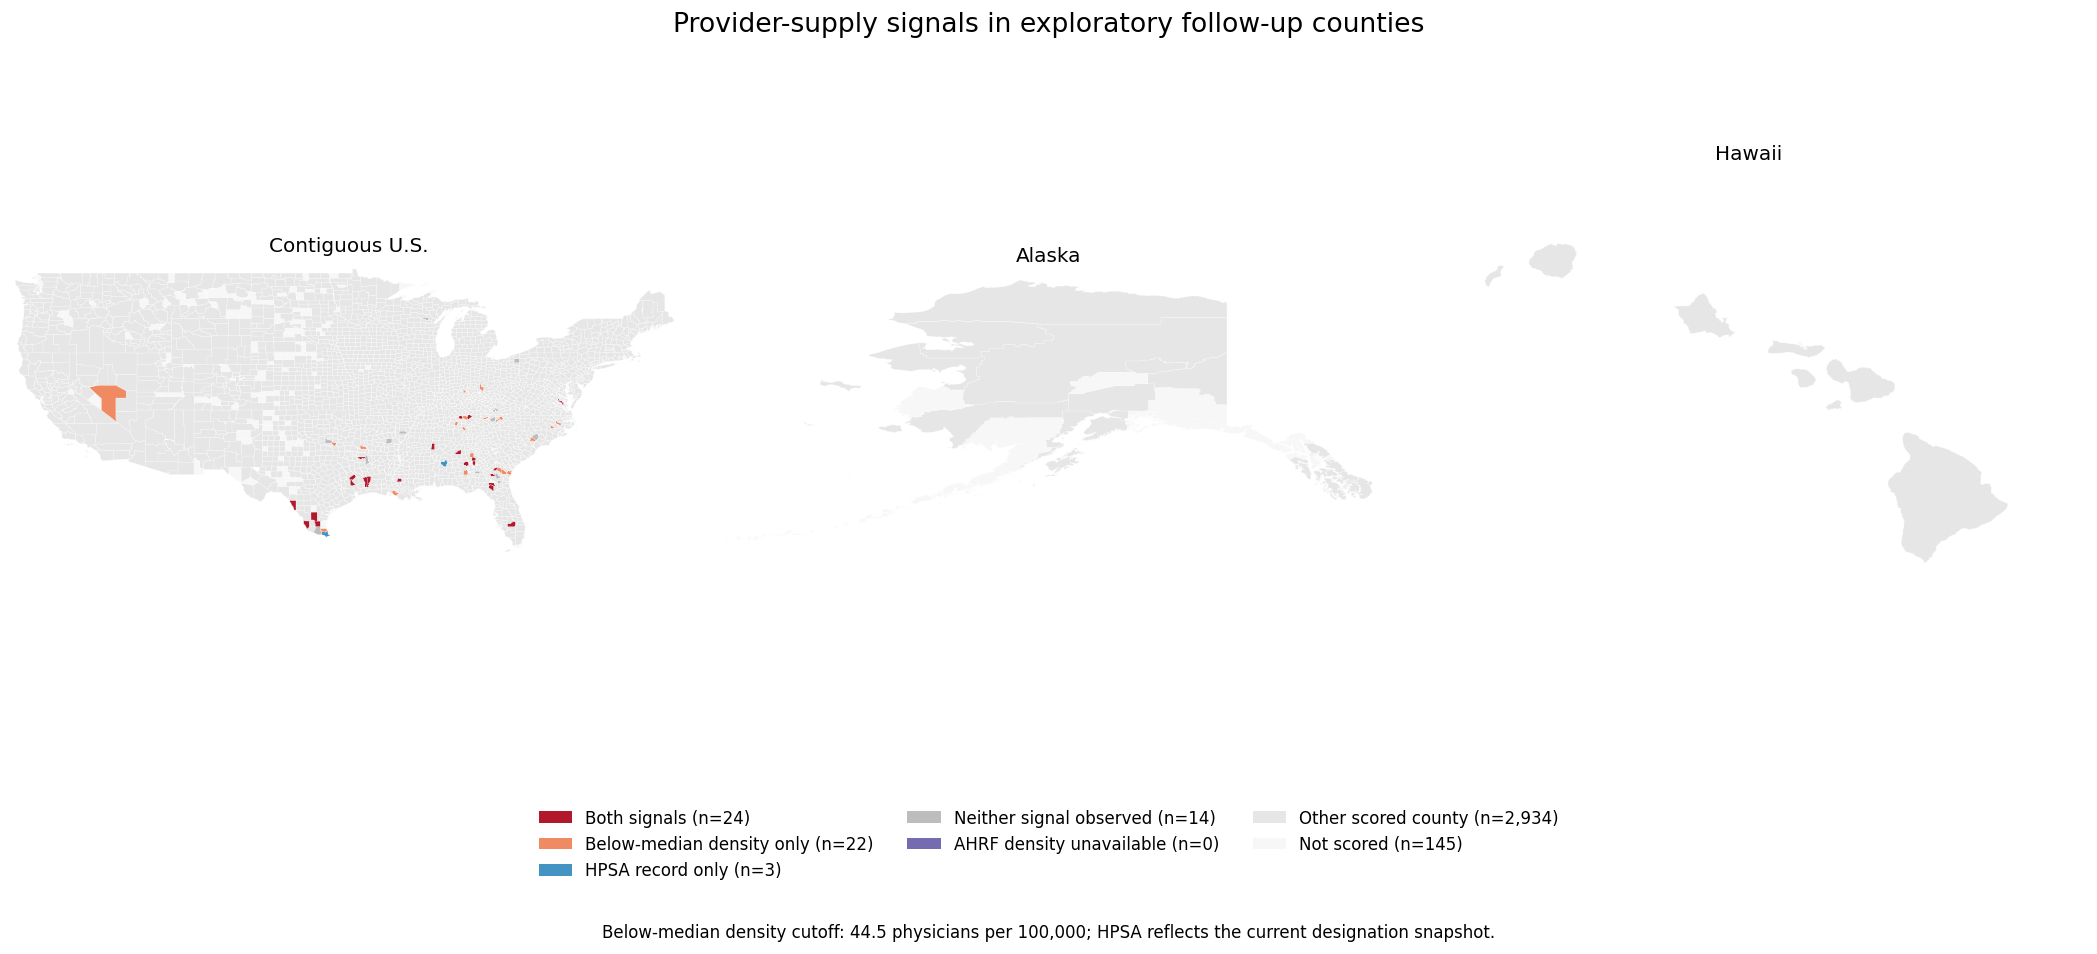

In [36]:
provider_map_labels = {
    "Below-median density + HPSA record": "Both signals",
    "Below-median density only": "Below-median density only",
    "HPSA record only": "HPSA record only",
    "Neither signal observed": "Neither signal observed",
    "AHRF density unavailable": "AHRF density unavailable",
}
provider_map_order = [
    "Both signals",
    "Below-median density only",
    "HPSA record only",
    "Neither signal observed",
    "AHRF density unavailable",
]
provider_map_colors = {
    "Both signals": "#b2182b",
    "Below-median density only": "#ef8a62",
    "HPSA record only": "#4393c3",
    "Neither signal observed": "#bdbdbd",
    "AHRF density unavailable": "#756bb1",
    "Other scored county": "#e6e6e6",
    "Not scored": "#f7f7f7",
}
triangulated_scored["ProviderSignalMapGroup"] = "Other scored county"
for pattern, map_label in provider_map_labels.items():
    map_mask = (
        triangulated_scored["FollowUpCandidate"]
        & triangulated_scored["ProviderSignalPattern"].eq(pattern)
    )
    triangulated_scored.loc[map_mask, "ProviderSignalMapGroup"] = map_label

shortlist_map_counts = (
    triangulated_scored.loc[
        triangulated_scored["FollowUpCandidate"], "ProviderSignalMapGroup"
    ]
    .value_counts()
    .reindex(provider_map_order, fill_value=0)
)
display(shortlist_map_counts.rename("Follow-up counties"))

provider_map_by_fips = triangulated_scored.set_index("CountyFIPS")["ProviderSignalMapGroup"]
mapped_fips = {
    county_fips
    for polygons in region_polygons.values()
    for _, county_fips in polygons
}
provider_map_counts = shortlist_map_counts.to_dict()
provider_map_counts["Other scored county"] = int(
    (~triangulated_scored["FollowUpCandidate"]).sum()
)
provider_map_counts["Not scored"] = len(
    mapped_fips - set(triangulated_scored["CountyFIPS"])
)

fig, axes = plt.subplots(1, 3, figsize=(18, 8))
for ax, (region, limits) in zip(axes, region_limits.items()):
    patches = []
    face_colors = []
    for vertices, county_fips in region_polygons[region]:
        group = provider_map_by_fips.get(county_fips, "Not scored")
        patches.append(MapPolygon(vertices, closed=True))
        face_colors.append(provider_map_colors[group])

    collection = PatchCollection(
        patches,
        facecolor=face_colors,
        edgecolor="white",
        linewidth=0.15,
    )
    ax.add_collection(collection)
    west, east, south, north = limits
    ax.set_xlim(west, east)
    ax.set_ylim(south, north)
    ax.set_aspect("equal", adjustable="box")
    ax.set_title(region)
    ax.set_axis_off()

provider_map_legend_labels = provider_map_order + [
    "Other scored county",
    "Not scored",
]
provider_map_legend = [
    Patch(
        facecolor=provider_map_colors[label],
        label=f"{label} (n={provider_map_counts[label]:,})",
    )
    for label in provider_map_legend_labels
]
fig.legend(
    handles=provider_map_legend,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.06),
    ncol=3,
    frameon=False,
)
fig.suptitle("Provider-supply signals in exploratory follow-up counties", fontsize=16)
fig.text(
    0.5,
    0.015,
    f"Below-median density cutoff: {overall_supply_median:.1f} physicians per 100,000; "
    "HPSA reflects the current designation snapshot.",
    ha="center",
    fontsize=10,
)
fig.subplots_adjust(left=0.02, right=0.98, bottom=0.25, top=0.88, wspace=0.04)
plt.show()

## Export a county-level review table

The final table keeps the original 62 exploratory follow-up counties together with the separate need, utilization, provider-density, and HPSA indicators. It also includes density flags for all three tested cutoffs so reviewers can see how each county changes under the sensitivity check. Rows are sorted by NeedScore for convenience; this is not a combined access ranking. The generated CSV is written to the ignored `data/processed/` folder and can be recreated by rerunning the notebook.

In [37]:
followup_review = triangulated_scored.loc[
    triangulated_scored["FollowUpCandidate"]
].copy()
if followup_review["CountyFIPS"].duplicated().any():
    raise ValueError("The follow-up review table contains duplicate county FIPS codes.")

scenario_count_by_fips = pd.Series(
    county_scenario_count.to_numpy(),
    index=score_df["CountyFIPS"],
)
followup_review["ServiceCutoffScenariosSelected"] = followup_review["CountyFIPS"].map(
    scenario_count_by_fips
)
if followup_review["ServiceCutoffScenariosSelected"].isna().any():
    raise ValueError("Some follow-up counties are missing cutoff-sensitivity counts.")
followup_review["ServiceCutoffScenariosSelected"] = (
    followup_review["ServiceCutoffScenariosSelected"].astype(int)
)
followup_review["SelectedUnderAllNineServiceCutoffs"] = (
    followup_review["ServiceCutoffScenariosSelected"].eq(9)
)

density_cutoff_values = dict(density_thresholds)
followup_review["Below25thPercentilePhysicianDensity"] = (
    followup_review["PrimaryCarePhysiciansPer100k"].lt(
        density_cutoff_values["25th percentile"]
    )
)
followup_review["BelowMedianPhysicianDensity"] = (
    followup_review["PrimaryCarePhysiciansPer100k"].lt(
        density_cutoff_values["50th percentile (median)"]
    )
)
followup_review["Below75thPercentilePhysicianDensity"] = (
    followup_review["PrimaryCarePhysiciansPer100k"].lt(
        density_cutoff_values["75th percentile"]
    )
)
review_columns = [
    "StateAbbr", "CountyName", "CountyFIPS", "NeedScore", "Quadrant",
    "ACUTE_HOSP_READMSN_PCT", "FQHC_RHC_VISITS_PER_1000_BENES",
    "OP_VISITS_PER_1000_BENES", "BENES_TOTAL_CNT",
    "ServiceCutoffScenariosSelected", "SelectedUnderAllNineServiceCutoffs",
    "PrimaryCarePhysiciansPer100k",
    "Below25thPercentilePhysicianDensity",
    "BelowMedianPhysicianDensity",
    "Below75thPercentilePhysicianDensity",
    "ActivePrimaryCareGeographicHPSARecords",
    "HasActivePrimaryCareGeographicHPSA", "ProviderSignalPattern",
]
followup_review_path = PROJECT_ROOT / "data/processed/followup_county_review.csv"
followup_review_path.parent.mkdir(parents=True, exist_ok=True)
followup_review = followup_review.sort_values(
    ["NeedScore", "StateAbbr", "CountyName"],
    ascending=[False, True, True],
)
followup_review[review_columns].to_csv(followup_review_path, index=False)
print(
    f"Saved {len(followup_review)} unique county rows to "
    f"{followup_review_path.relative_to(PROJECT_ROOT)}."
)
display(followup_review[review_columns].head(10).round(2))

Saved 63 unique county rows to data/processed/followup_county_review.csv.


,StateAbbr,CountyName,CountyFIPS,NeedScore,Quadrant,ACUTE_HOSP_READMSN_PCT,FQHC_RHC_VISITS_PER_1000_BENES,OP_VISITS_PER_1000_BENES,BENES_TOTAL_CNT,ServiceCutoffScenariosSelected,SelectedUnderAllNineServiceCutoffs,PrimaryCarePhysiciansPer100k,Below25thPercentilePhysicianDensity,BelowMedianPhysicianDensity,Below75thPercentilePhysicianDensity,ActivePrimaryCareGeographicHPSARecords,HasActivePrimaryCareGeographicHPSA,ProviderSignalPattern
151,AR,St. Francis,05123,5.70,High need / higher readmissions,0.21,966.70,3919.88,5303.0,6,False,54.99,False,False,True,0,False,Neither signal observed
363,GA,Atkinson,13003,5.35,High need / higher readmissions,0.20,713.24,4857.84,1566.0,4,False,0.00,True,True,True,1,True,Below-median density + HPSA record
2341,TN,Fentress,47049,5.32,High need / higher readmissions,0.19,271.09,2666.45,6318.0,6,False,24.84,True,True,True,1,True,Below-median density + HPSA record
2566,TX,Newton,48351,5.30,High need / higher readmissions,0.20,724.37,3747.15,3108.0,6,False,0.00,True,True,True,1,True,Below-median density + HPSA record
40,AL,Dallas,01047,5.24,High need / higher readmissions,0.20,356.44,3087.56,10288.0,6,False,115.35,False,False,False,1,True,HPSA record only
2637,TX,Zapata,48505,4.94,High need / higher readmissions,0.30,941.77,2473.90,2210.0,6,False,0.00,True,True,True,1,True,Below-median density + HPSA record
2080,OK,Marshall,40095,4.69,High need / higher readmissions,0.20,846.80,4338.22,4431.0,4,False,24.77,True,True,True,0,False,Below-median density only
2360,TN,Jackson,47087,4.68,High need / higher readmissions,0.22,796.78,3371.56,3295.0,6,False,8.08,True,True,True,1,True,Below-median density + HPSA record
2698,VA,Emporia,51595,4.68,High need / higher readmissions,0.22,305.22,3341.37,1344.0,6,False,0.00,True,True,True,1,True,Below-median density + HPSA record
317,FL,Hamilton,12047,4.56,High need / higher readmissions,0.20,394.24,2473.84,3575.0,6,False,13.95,True,True,True,1,True,Below-median density + HPSA record


In [38]:
score_df.to_csv(
    PROJECT_ROOT / "data/processed/county_need_readmission_quadrants_2024.csv",
    index=False,
)